<a href="https://colab.research.google.com/github/RoihansLab/Data-Mining-Project/blob/main/youtube_comment_sentiment/Data_Preparation/data_preparation_labeling.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Analisis Sikap Publik terhadap AI yang Menggantikan Pekerjaan Manusia Berdasarkan Komentar YouTube**

**Mata Kuliah:** Data Mining

**Nama Anggota Kelompok:**

1.   Muhammad Rafa Enrico (Ketua - 4.33.24.2.15)
2.   Roihan Saputra (4.33.24.2.20)

**Kelas TI-3C**

**Program Studi:** D4 Teknologi Rekayasa Komputer, Politeknik Negeri Semarang

## Rumusan Masalah
1. Bagaimana sebaran sikap publik (positif, negatif, dan perlu ditinjau) terhadap isu AI yang menggantikan pekerjaan manusia berdasarkan komentar YouTube?
2. Kombinasi fitur (embedding e5-large dan TF-IDF) dan algoritma klasifikasi (SVM linear, Naive Bayes, Logistic Regression, KNN, serta *fine-tuning* XLM-RoBERTa) manakah yang paling seimbang antara performa (macro-F1), *good fit*, dan *robustness* untuk mengotomatisasi deteksi sikap publik?

## Tujuan
1. Mengetahui sebaran sikap publik terhadap isu AI yang menggantikan pekerjaan manusia berdasarkan komentar YouTube.
2. Menemukan model klasifikasi yang performanya baik, tidak overfitting (*good fit*), dan stabil (*robust*), termasuk pada komentar dari video yang belum pernah dilihat, untuk mengotomatisasi pelabelan sikap publik pada komentar baru.

## Alur Notebook
1. **Import Library** dan kunci random state (`SEED = 42`).
2. **Memuat dan Memahami Data** hasil *scraping* 6 video YouTube.
3. **Preprocessing Data**: membersihkan data mentah (duplikat, spam, mention, URL, bahasa, dan lain-lain) sampai menjadi data bersih `youtube_comments_clean_EDA.csv`.
4. **EDA** untuk melihat komposisi data bersih.
5. **Pelabelan Data** oleh manusia (449 komentar) dan Claude Opus 5.5 (3.486 komentar), menghasilkan `youtube_comments_label_final.csv` yang siap digunakan untuk pemodelan klasifikasi, lalu **uji kualitas label** (5.3) dan **pola sikap publik** (5.5).


# **1. Import Library**

Library untuk notebook ini dipasang dan di-import di sel ini. `SEED = 42` dipakai sebagai `random_state` supaya pengambilan contoh acak bisa diulang persis sama.

| Library | Kegunaan di notebook ini |
|---|---|
| `pandas` | membaca, membersihkan, dan menyimpan data dalam bentuk tabel |
| `matplotlib` | membuat grafik EDA (Bab 4) |
| `lingua` | mendeteksi bahasa komentar, Indonesia atau Inggris (Bab 3.8) |
| `os` | mencari lokasi berkas data (Google Colab atau laptop) |

Library untuk text preprocessing, ekstraksi fitur, klasifikasi, dan optimasi di-import di notebook `classification_modeling.ipynb`.

In [10]:
# Pasang library yang belum ada (Google Colab / Antigravity)
%pip install lingua-language-detector pandas matplotlib scikit-learn --quiet

In [11]:
import os
import pandas as pd
import matplotlib.pyplot as plt
from lingua import Language, LanguageDetectorBuilder   # deteksi bahasa (Bab 3.8)
from sklearn.metrics import f1_score, accuracy_score, cohen_kappa_score   # uji kualitas label (Bab 5.3)

SEED = 42   # dipakai sebagai random_state supaya hasil acak selalu sama

# **2. Data Understanding**

Bab ini mengenali data mentah sebelum dibersihkan: dari mana data berasal, apa isi setiap kolom, bagaimana tipe datanya, dan apa ciri-ciri tiap kolom. Temuan di bab ini menjadi dasar langkah-langkah preprocessing pada Bab 3.

## **2.1 Sumber Data**

Data yang dipakai adalah data primer hasil *web scraping* komentar YouTube memakai skrip `datasets/scrape_youtube_comments.py` (library `youtube-comment-downloader`, komentar diurutkan dari yang terpopuler). Pengambilan dilakukan pada **17 Oktober 2026**.

Data diambil dari 6 video bertema AI yang menggantikan pekerjaan manusia, terdiri dari 2 video berbahasa Indonesia dan 4 video berbahasa Inggris:

| Bahasa | Judul video | ID video |
|---|---|---|
| Indonesia | Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI! | `t2WmNcToB3I` |
| Indonesia | Manusia Belum Tergantikan AI Karena Satu Hambatan Ini | `F8pz5wIO6gA` |
| Inggris | Humans Need Not Apply - CGP Grey | `7Pq-S557XQU` |
| Inggris | The EXACT moment AI took my job... | `SDich6serU0` |
| Inggris | UK unemployment soars: is AI already taking our jobs? | `s1c4Ji6tNdw` |
| Inggris | AI is taking their jobs. But they're fighting back. | `0LOHWGQwKtM` |

**Alasan pemilihan video.** Video dipilih secara **purposif** (sengaja dipilih berdasarkan kriteria, bukan acak), dengan kriteria:
1. membahas tema yang sama, yaitu **AI yang menggantikan pekerjaan manusia**;
2. mencakup **dua bahasa** (2 video Indonesia dan 4 video Inggris), supaya sikap publik Indonesia dan internasional sama-sama terwakili;
3. memiliki cukup banyak komentar untuk dianalisis.

Karena hanya 6 video yang dipilih secara purposif, hasil penelitian ini adalah **studi kasus** pada keenam video tersebut, bukan gambaran seluruh pengguna internet.

Pengambilan dibatasi **1.500 komentar per video** (`MAX_COMMENTS_PER_VIDEO`) supaya video CGP Grey, yang memiliki sekitar 48 ribu komentar, tidak mendominasi data. Video dengan komentar lebih sedikit dari batas tersebut terambil seluruhnya.

## **2.2 Memuat Data**

Data mentah dibaca dari `youtube_comments.csv` langsung dari **GitHub**, jadi notebook bisa dijalankan di **Google Colab** maupun **Antigravity** tanpa upload file (butuh koneksi internet). Kolom yang diambil saat *scraping*:

1. `video_url`: URL video sumber komentar.
2. `author`: nama akun penulis komentar.
3. `comment`: isi teks komentar.
4. `likes`: jumlah *like* pada komentar.
5. `time`: waktu komentar dibuat, relatif terhadap tanggal *web scraping* dilakukan.

Nama akun (`author`) tidak ditampilkan pada output untuk menjaga privasi penulis komentar.

In [12]:
# Dataset diambil langsung dari GitHub,
# jadi bisa dipakai di Google Colab maupun Antigravity tanpa upload file (butuh internet)
url = "https://raw.githubusercontent.com/RoihansLab/Data-Mining-Project/main/datasets/youtube_comments.csv"

df = pd.read_csv(url)
print("Jumlah baris:", len(df))

Jumlah baris: 4458


In [13]:
# Nama akun tidak ditampilkan untuk menjaga privasi
df.drop(columns="author").head()

,video_url,comment,likes,time
0,https://www.youtube.com/watch?v=t2WmNcToB3I,Bahas imigrant maroko yg nyebrang ke spanyol donk bang,413,2 maanden geleden
1,https://www.youtube.com/watch?v=t2WmNcToB3I,"Menurut saya jika semua pengusaha berpikiran sama untuk mengganti manusia dengan AI demi memotong biaya, mereka seda...",189,2 maanden geleden
2,https://www.youtube.com/watch?v=t2WmNcToB3I,"jujur ya sebagai seorang yang bekerja di bidang desain, seni, ilustrator agak sedih dengan keadaan apa-apa didesain ...",6,2 maanden geleden (bewerkt)
3,https://www.youtube.com/watch?v=t2WmNcToB3I,"Gw sebagai illustrator susah bener dapet klien baru karena orang udh ngerasa 'ga butuh' jasa illustrator, terus oran...",588,2 maanden geleden
4,https://www.youtube.com/watch?v=t2WmNcToB3I,Niat untung -> efesiensi phk->produksi meningkat->tidak banyak pembeli karna banyak pengangguran->barang numpuk->ma...,85,2 maanden geleden


**Hasil:** data mentah berisi **4.458 komentar** dengan 5 kolom. Jumlah ini menjadi titik awal untuk menghitung berapa baris yang dibuang pada setiap langkah preprocessing.

## **2.3 Struktur dan Tipe Data**

`info()` menampilkan jumlah baris, jumlah nilai yang terisi pada setiap kolom, dan tipe data setiap kolom.

In [14]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4458 entries, 0 to 4457
Data columns (total 5 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   video_url  4458 non-null   object
 1   author     4458 non-null   object
 2   comment    4458 non-null   object
 3   likes      4458 non-null   object
 4   time       4458 non-null   object
dtypes: object(5)
memory usage: 174.3+ KB


**Hasil:**

Ada 4.458 baris dan 5 kolom tanpa nilai kosong. Semua kolom bertipe teks (`object`), termasuk `likes` yang seharusnya angka, karena hasil *scraping* menyimpan jumlah like sebagai teks dengan singkatan seperti `6,5K`. Kolom `likes` diubah menjadi angka pada 3.9, sedangkan kolom `time` dibuang setelah pengecekan duplikat (3.2).

## **2.4 Statistik Deskriptif**

`describe()` merangkum ciri setiap kolom. Karena semua kolom masih bertipe teks, ringkasannya berupa: `count` adalah jumlah nilai yang terisi, `unique` jumlah nilai yang berbeda, `top` nilai yang paling sering muncul, dan `freq` berapa kali nilai `top` muncul.

In [15]:
# Nama akun tidak ditampilkan untuk menjaga privasi, cukup jumlah akun uniknya
print("Jumlah akun unik:", df["author"].nunique())
df.drop(columns="author").describe().T

Jumlah akun unik: 3320


,count,unique,top,freq
video_url,4458,6,https://www.youtube.com/watch?v=7Pq-S557XQU,1500
comment,4458,4406,Up,6
likes,4458,241,0,2400
time,4458,62,2 maanden geleden,933


**Hasil:**

1. **`video_url`:** ada 6 video. Nilai terbanyak adalah 1.500 komentar milik video CGP Grey, sesuai batas pengambilan per video.
2. **`author`:** ada 3.320 akun berbeda dari 4.458 komentar, jadi sebagian akun menulis lebih dari satu komentar (terbanyak 36 komentar dari satu akun). Nama akun termasuk identitas pribadi, sehingga diganti `author_id` pada 3.3.
3. **`comment`:** hanya 4.406 teks yang unik, sehingga ada 52 komentar kembar (ditangani pada 3.2 dan 3.6). Komentar yang paling sering muncul adalah "Up" (6 kali), tanda banyak komentar sangat pendek tanpa opini (ditangani pada 3.7).
4. **`likes`:** nilai terbanyak adalah 0 like (2.400 komentar atau 53,8%), jadi sebagian besar komentar tidak mendapat like.
5. **`time`:** ada 62 nilai berbeda berupa waktu relatif berbahasa Belanda, misalnya "2 maanden geleden" (2 bulan yang lalu) yang muncul 933 kali. Bahasa Belanda muncul karena pengaturan bahasa saat *scraping*. Nilai ini tidak dapat diubah menjadi tanggal pasti, sehingga kolom `time` dibuang.

## **2.5 Jumlah Komentar per Video**

Langkah ini menghitung berapa komentar yang terambil dari setiap video pada data mentah. ID video dapat dicocokkan dengan judulnya pada tabel di 2.1.

In [16]:
per_video = df["video_url"].str[-11:].value_counts()
pd.DataFrame({
    "ID video": per_video.index,
    "Jumlah komentar": per_video.values,
    "Persen (%)": (per_video.values / len(df) * 100).round(1),
})

,ID video,Jumlah komentar,Persen (%)
0,7Pq-S557XQU,1500,33.6
1,s1c4Ji6tNdw,912,20.5
2,F8pz5wIO6gA,867,19.4
3,t2WmNcToB3I,819,18.4
4,SDich6serU0,230,5.2
5,0LOHWGQwKtM,130,2.9


**Hasil:**

| Video | Jumlah komentar | Persen |
|---|---|---|
| Humans Need Not Apply - CGP Grey (EN) | 1.500 | 33,6% |
| UK unemployment soars: is AI already taking our jobs? (EN) | 912 | 20,5% |
| Manusia Belum Tergantikan AI Karena Satu Hambatan Ini (ID) | 867 | 19,4% |
| Pekerja Latih Robot Untuk Gantikan Mereka! (ID) | 819 | 18,4% |
| The EXACT moment AI took my job... (EN) | 230 | 5,2% |
| AI is taking their jobs. But they're fighting back. (EN) | 130 | 2,9% |

1. Video CGP Grey terambil tepat **1.500 komentar**, artinya batas pengambilan per video benar-benar terpakai. Tanpa batas ini, video tersebut (sekitar 48 ribu komentar) akan menguasai hampir seluruh data.
2. Jumlah komentar antarvideo **tidak seimbang**: video terbanyak sekitar 11 kali lebih banyak daripada video tersedikit (130 komentar). Karena itu, perbandingan antarvideo pada tahap analisis dibaca sebagai persentase, bukan jumlah mentah.
3. Dua video berbahasa Indonesia menyumbang 1.686 komentar (37,8%) dan empat video berbahasa Inggris menyumbang 2.772 komentar (62,2%).

## **2.6 Contoh Isi Komentar**

Langkah ini menampilkan contoh komentar mentah untuk melihat seperti apa data sebelum dibersihkan. Bagian pertama berisi 5 komentar acak. Bagian kedua menghitung beberapa jenis masalah yang sering muncul. Nama akun yang disebut dengan mention ditampilkan sebagai `@[akun]` untuk menjaga privasi.

In [17]:
pd.set_option("display.max_colwidth", 120)   # tampilkan teks komentar lebih panjang

# 1. Ambil 5 komentar acak
contoh = df.sample(5, random_state=SEED)["comment"]

# 2. Samarkan nama akun yang di-mention, lalu potong supaya tidak terlalu panjang
contoh = contoh.str.replace(r"@\S+", "@[akun]", regex=True)
contoh.str[:120]

,comment
387,Ai harus ditolak di berbagai sektor pekerjaan
3482,I think the OP was rather suggesting that what you describe is the profile of a lot of CEOs already!
1330,😊😊
2905,That is the point Tysej4
1833,@[akun] i don't have a basement i live in a flat so to me a basement is someone's home


In [18]:
# Hitung jumlah komentar untuk setiap jenis masalah
masalah = {
    "Mention (@username)": df["comment"].str.contains(r"@\S+"),
    "URL": df["comment"].str.contains(r"https?://\S+|www\.\S+"),
    "Karakter tak terlihat": df["comment"].str.contains("[\u200b\u200c\u2060\ufeff]"),
    "Spasi ganda, spasi di tepi, atau baris baru": df["comment"] != df["comment"].str.split().str.join(" "),
    "Spam dengan huruf bergaya": df["comment"].str.contains("[\U0001D400-\U0001D7FF]"),
    "Sangat pendek (kurang dari 3 kata)": df["comment"].str.split().str.len() < 3,
}

for jenis, ada in masalah.items():
    print(jenis, ":", ada.sum(), "komentar")

Mention (@username) : 923 komentar
URL : 11 komentar
Karakter tak terlihat : 273 komentar
Spasi ganda, spasi di tepi, atau baris baru : 1581 komentar
Spam dengan huruf bergaya : 28 komentar
Sangat pendek (kurang dari 3 kata) : 301 komentar


**Hasil:**

Dari 5 komentar acak, terlihat bahwa data bercampur bahasa Indonesia dan Inggris, ada komentar yang hanya berisi emoji (`😊😊`), dan ada komentar balasan yang diawali mention. Hitungan jenis masalah menunjukkan:

| Jenis masalah | Jumlah komentar | Ditangani pada |
|---|---|---|
| Mention (@username) | 923 | 3.4 |
| URL | 11 | 3.4 |
| Karakter tak terlihat (misalnya *zero-width space*) | 273 | 3.4 |
| Spasi ganda, spasi di tepi, atau baris baru | 1.581 | 3.4 |
| Spam dengan huruf bergaya (promosi judi online) | 28 | 3.5 |
| Sangat pendek, kurang dari 3 kata (misalnya "Up", "exactly!!") | 301 | 3.7 |

Masalah ini menjadi dasar langkah pembersihan pada Bab 3. Jumlahnya bisa sedikit berbeda dengan hasil pengecekan di Bab 3 karena di sana pengecekan dilakukan setelah langkah sebelumnya (misalnya setelah duplikat dihapus).

# **3. Preprocessing Data**

Preprocessing membersihkan data mentah hasil *scraping* (4.458 komentar) supaya yang tersisa hanya komentar yang layak dianalisis dan dilabeli. Setiap langkah mengikuti pola yang sama:

1. **Pengecekan:** menghitung berapa data yang bermasalah.
2. **Pembersihan:** memperbaiki atau membuang data tersebut.
3. **Verifikasi:** menghitung ulang untuk memastikan masalahnya sudah 0.

| Bagian | Langkah | Yang berubah |
|---|---|---|
| 3.1 | Nilai kosong | tidak ada (hanya pengecekan) |
| 3.2 | Duplikat baris | baris dibuang |
| 3.3 | Penyesuaian kolom `video_url` dan `author` | kolom diubah |
| 3.4 | Pembersihan teks: karakter tak terlihat, mention, URL, spasi | isi komentar diperbaiki |
| 3.5 | Spam judi online | baris dibuang |
| 3.6 | Duplikat isi komentar | baris dibuang |
| 3.7 | Komentar kurang dari 3 kata | baris dibuang |
| 3.8 | Deteksi bahasa | baris dibuang |
| 3.9 | Konversi kolom `likes` | kolom diubah |
| 3.10 | Menyimpan data bersih | - |
| 3.11 | Ringkasan preprocessing | - |

> Bab ini adalah **preprocessing awal**: data dibersihkan tanpa mengubah makna komentar, karena pelabelan di Bab 5 membutuhkan teks yang masih utuh. Pengolahan teks khusus untuk model (huruf kecil, *stopword*, *stemming*, dan lain-lain) dilakukan terpisah pada notebook klasifikasi.

## **3.1 Nilai Kosong (Null)**

**Tujuan:** memastikan tidak ada sel kosong pada kelima kolom data mentah.

**Mengapa perlu dicek?**
1. Komentar yang kosong tidak memuat opini, sehingga tidak bisa dilabeli maupun dipelajari model.
2. Sebagian besar fungsi pengolahan teks dan algoritma *machine learning* (termasuk TF-IDF, Decision Tree, Naïve Bayes, Random Forest, dan Logistic Regression) tidak dapat memproses nilai kosong dan akan menghasilkan error.

**Cara:** `isnull().sum()` menghitung jumlah sel kosong di setiap kolom.

In [19]:
df.isnull().sum()

,0
video_url,0
author,0
comment,0
likes,0
time,0


**Hasil:** kelima kolom (`video_url`, `author`, `comment`, `likes`, dan `time`) bernilai 0, artinya tidak ada sel kosong. Tidak ada baris yang dibuang, dan data tetap **4.458 baris**.

## **3.2 Duplikat Baris**

**Tujuan:** membuang baris yang isinya sama persis di semua kolom (video, penulis, isi komentar, jumlah *like*, dan waktu). Baris seperti ini adalah salinan yang terambil dua kali saat *scraping*, bukan dua komentar yang berbeda.

**Mengapa perlu dibuang?**
1. **Mencegah kebocoran data (*data leakage*):** salinan bisa masuk ke data latih dan data uji sekaligus, sehingga model diuji dengan data yang sudah pernah dilihatnya dan akurasinya tampak lebih tinggi dari kenyataan.
2. **Mencegah bobot kata yang bias:** komentar yang muncul berkali-kali membuat kata-katanya dianggap lebih penting dalam pembobotan TF-IDF.
3. **Sebaran data tetap jujur:** satu komentar tidak dihitung dua kali saat menghitung sebaran sikap.

**Cara:** `duplicated()` menandai baris yang sama persis dengan baris sebelumnya. Baris pertama disimpan dan salinannya dibuang dengan `drop_duplicates()`.

In [20]:
df.duplicated().sum()

np.int64(11)

**Hasil pengecekan:** ditemukan **11 baris duplikat**.

**Pembersihan:** `drop_duplicates()` membuang salinan dan menyimpan baris pertama dari setiap kelompok.

In [21]:
df.drop_duplicates(inplace=True)

**Verifikasi:** menghitung ulang baris duplikat (harus 0) dan jumlah baris yang tersisa, lalu menampilkan 5 baris pertama. Kolom `author` disembunyikan untuk menjaga privasi penulis.

In [22]:
print("Sisa baris duplikat:", df.duplicated().sum())
print("Jumlah baris:", len(df))
df.drop(columns="author").head()

Sisa baris duplikat: 0
Jumlah baris: 4447


,video_url,comment,likes,time
0,https://www.youtube.com/watch?v=t2WmNcToB3I,Bahas imigrant maroko yg nyebrang ke spanyol donk bang,413,2 maanden geleden
1,https://www.youtube.com/watch?v=t2WmNcToB3I,"Menurut saya jika semua pengusaha berpikiran sama untuk mengganti manusia dengan AI demi memotong biaya, mereka seda...",189,2 maanden geleden
2,https://www.youtube.com/watch?v=t2WmNcToB3I,"jujur ya sebagai seorang yang bekerja di bidang desain, seni, ilustrator agak sedih dengan keadaan apa-apa didesain ...",6,2 maanden geleden (bewerkt)
3,https://www.youtube.com/watch?v=t2WmNcToB3I,"Gw sebagai illustrator susah bener dapet klien baru karena orang udh ngerasa 'ga butuh' jasa illustrator, terus oran...",588,2 maanden geleden
4,https://www.youtube.com/watch?v=t2WmNcToB3I,Niat untung -> efesiensi phk->produksi meningkat->tidak banyak pembeli karna banyak pengangguran->barang numpuk->ma...,85,2 maanden geleden


**Membuang kolom `time`:** kolom ini berisi waktu relatif terhadap tanggal *scraping* dalam bahasa Belanda, misalnya "2 maanden geleden" (2 bulan yang lalu). Nilainya hanya perkiraan kasar, tidak bisa diubah menjadi tanggal pasti, dan tidak dipakai dalam analisis (perubahan sikap dari waktu ke waktu **bukan fokus penelitian ini**), sehingga dibuang. Kolom ini sengaja dibuang **setelah** pengecekan duplikat karena ikut menentukan apakah dua baris benar-benar sama. Kolom `likes` tetap disimpan karena dipakai di EDA (Bab 4) dan dikonversi menjadi angka di 3.9.

In [23]:
df = df.drop(columns=["time"])
df.drop(columns="author").head()

,video_url,comment,likes
0,https://www.youtube.com/watch?v=t2WmNcToB3I,Bahas imigrant maroko yg nyebrang ke spanyol donk bang,413
1,https://www.youtube.com/watch?v=t2WmNcToB3I,"Menurut saya jika semua pengusaha berpikiran sama untuk mengganti manusia dengan AI demi memotong biaya, mereka seda...",189
2,https://www.youtube.com/watch?v=t2WmNcToB3I,"jujur ya sebagai seorang yang bekerja di bidang desain, seni, ilustrator agak sedih dengan keadaan apa-apa didesain ...",6
3,https://www.youtube.com/watch?v=t2WmNcToB3I,"Gw sebagai illustrator susah bener dapet klien baru karena orang udh ngerasa 'ga butuh' jasa illustrator, terus oran...",588
4,https://www.youtube.com/watch?v=t2WmNcToB3I,Niat untung -> efesiensi phk->produksi meningkat->tidak banyak pembeli karna banyak pengangguran->barang numpuk->ma...,85


**Hasil:** duplikat tersisa 0 dan data turun dari 4.458 menjadi **4.447 baris** (11 baris dibuang). Kolom yang tersisa adalah `video_url`, `author`, `comment`, dan `likes`.

## **3.3 Penyesuaian Kolom `video_url` dan `author`**

**Tujuan:** mengubah dua kolom menjadi bentuk yang lebih mudah dibaca dan lebih aman. Jumlah baris tidak berubah pada langkah ini.

| Kolom lama | Kolom baru | Alasan |
|---|---|---|
| `video_url` | `video_title` | URL panjang sulit dibaca. Judul video langsung menjelaskan sumber komentar pada tabel dan grafik EDA, dan juga dipakai untuk mengelompokkan komentar per video pada tahap klasifikasi. |
| `author` | `author_id` | Nama akun adalah identitas pribadi. Nama diganti nomor urut (anonimisasi), sehingga identitas penulis tidak tersimpan, tetapi komentar dari akun yang sama tetap bisa dikenali. |

### **a. `video_url` → `video_title`**

**Cara:** ID video adalah 11 karakter terakhir URL (misalnya `7Pq-S557XQU`). ID ini dicocokkan dengan kamus `title` yang berisi judul keenam video.

**Pengecekan:** menghitung jumlah video unik dan jumlah komentar untuk setiap ID video.

In [24]:
print("Jumlah video unik:", df["video_url"].nunique())
df["video_url"].str[-11:].value_counts()

Jumlah video unik: 6


,count
video_url,
7Pq-S557XQU,1497
s1c4Ji6tNdw,908
F8pz5wIO6gA,865
t2WmNcToB3I,817
SDich6serU0,230
0LOHWGQwKtM,130


**Hasil pengecekan:** ada 6 ID video, sesuai dengan jumlah video yang di-*scraping*, jadi keenamnya perlu ada di kamus `title`.

**Konversi:** membuat kolom `video_title` dari ID video memakai kamus `title`.

In [25]:
title = {
    "t2WmNcToB3I": "Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!",
    "F8pz5wIO6gA": "Manusia Belum Tergantikan AI Karena Satu Hambatan Ini",
    "7Pq-S557XQU": "Humans Need Not Apply - CGP Grey",
    "SDich6serU0": "The EXACT moment AI took my job...",
    "s1c4Ji6tNdw": "UK unemployment soars: is AI already taking our jobs?",
    "0LOHWGQwKtM": "AI is taking their jobs. But they're fighting back.",
}

df["video_title"] = df["video_url"].str[-11:].map(title)

**Verifikasi:** menghitung baris yang gagal mendapat judul (harus 0) dan jumlah komentar per judul.

In [26]:
print("Baris tanpa judul:", df["video_title"].isna().sum())
df["video_title"].value_counts()

Baris tanpa judul: 0


,count
video_title,
Humans Need Not Apply - CGP Grey,1497
UK unemployment soars: is AI already taking our jobs?,908
Manusia Belum Tergantikan AI Karena Satu Hambatan Ini,865
Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,817
The EXACT moment AI took my job...,230
AI is taking their jobs. But they're fighting back.,130


**Hasil:** 0 baris gagal, artinya keenam ID video berhasil dipetakan ke judulnya. Jumlah komentar per judul sama dengan jumlah per ID pada pengecekan.

**Memilih kolom:** kolom `video_url` tidak diambil lagi karena sudah diwakili `video_title`. Urutan kolom menjadi `video_title`, `author`, `comment`, dan `likes`.

In [27]:
df = df[["video_title", "author", "comment", "likes"]]
df.drop(columns="author").head()

,video_title,comment,likes
0,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,Bahas imigrant maroko yg nyebrang ke spanyol donk bang,413
1,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,"Menurut saya jika semua pengusaha berpikiran sama untuk mengganti manusia dengan AI demi memotong biaya, mereka seda...",189
2,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,"jujur ya sebagai seorang yang bekerja di bidang desain, seni, ilustrator agak sedih dengan keadaan apa-apa didesain ...",6
3,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,"Gw sebagai illustrator susah bener dapet klien baru karena orang udh ngerasa 'ga butuh' jasa illustrator, terus oran...",588
4,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,Niat untung -> efesiensi phk->produksi meningkat->tidak banyak pembeli karna banyak pengangguran->barang numpuk->ma...,85


### **b. `author` → `author_id`**

**Cara:** `factorize()` memberi nomor urut, mulai dari 0, untuk setiap nama akun yang berbeda. Akun yang sama selalu mendapat nomor yang sama.

**Pengecekan:** menghitung jumlah akun unik. Nama akunnya sendiri tidak ditampilkan untuk menjaga privasi.

In [28]:
print("Jumlah akun unik:", df["author"].nunique())

Jumlah akun unik: 3320


**Konversi:** membuat kolom `author_id` berisi nomor urut setiap akun.

In [29]:
df["author_id"] = df["author"].factorize()[0]

**Verifikasi:** memastikan jumlah nomor unik sama dengan jumlah akun unik dan setiap akun hanya mendapat satu nomor, lalu menampilkan 5 nomor pertama.

In [30]:
print("Jumlah author_id unik:", df["author_id"].nunique())
print("Setiap akun hanya punya satu nomor:", df.groupby("author")["author_id"].nunique().max() == 1)
df["author_id"].head()

Jumlah author_id unik: 3320
Setiap akun hanya punya satu nomor: True


,author_id
0,0
1,1
2,2
3,3
4,4


**Hasil:** ada **3.320 akun unik** dari 4.447 komentar, dan masing-masing mendapat tepat satu nomor. Artinya sebagian akun menulis lebih dari satu komentar.

**Membuang kolom `author`:** setelah nomor terbentuk, nama akun asli dibuang supaya data yang disimpan dan dibagikan tidak lagi memuat identitas penulis.

In [31]:
df.drop(columns=["author"], inplace=True)
print("Kolom sekarang:", list(df.columns))
df.head()

Kolom sekarang: ['video_title', 'comment', 'likes', 'author_id']


,video_title,comment,likes,author_id
0,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,Bahas imigrant maroko yg nyebrang ke spanyol donk bang,413,0
1,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,"Menurut saya jika semua pengusaha berpikiran sama untuk mengganti manusia dengan AI demi memotong biaya, mereka seda...",189,1
2,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,"jujur ya sebagai seorang yang bekerja di bidang desain, seni, ilustrator agak sedih dengan keadaan apa-apa didesain ...",6,2
3,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,"Gw sebagai illustrator susah bener dapet klien baru karena orang udh ngerasa 'ga butuh' jasa illustrator, terus oran...",588,3
4,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,Niat untung -> efesiensi phk->produksi meningkat->tidak banyak pembeli karna banyak pengangguran->barang numpuk->ma...,85,4


**Hasil:** data sekarang memiliki 4 kolom, yaitu `video_title`, `comment`, `likes`, dan `author_id`. Jumlah baris tetap **4.447**.

## **3.4 Pembersihan Teks**

**Tujuan:** merapikan isi kolom `comment` dari unsur yang bukan opini, tanpa mengubah makna komentar. Langkah ini hanya memperbaiki teks dan tidak membuang baris.

| Bagian | Yang dibersihkan | Perlakuan |
|---|---|---|
| 3.4.1 | Karakter tak terlihat dan spasi khusus | dibuang atau diganti spasi biasa |
| 3.4.2 | Mention (`@username`) | diganti spasi |
| 3.4.3 | URL | diganti spasi |
| 3.4.4 | Spasi ganda, spasi di tepi, dan baris baru | dirapikan menjadi satu spasi |

**Yang sengaja tidak dibuang:** huruf besar-kecil, emoji, dan tanda baca. Ketiganya ikut membawa sikap penulis, misalnya "TAKUT BANGET 😭" terasa lebih kuat daripada "takut banget", dan tetap bisa dibaca oleh pelabel (Claude).

### **3.4.1 Karakter Tak Terlihat dan Spasi Khusus**

**Tujuan:** membuang karakter yang tidak tampak di layar dan menyeragamkan jenis spasi.

1. **Karakter tak terlihat** seperti *zero-width space* (U+200B), *zero-width non-joiner* (U+200C), *word joiner* (U+2060), dan BOM (U+FEFF). Karakter ini tidak terlihat, tetapi membuat dua kata yang tampak sama dianggap berbeda oleh komputer, sehingga **dibuang**.
2. **Spasi khusus** seperti *non-breaking space* (U+00A0). Bentuknya sama dengan spasi biasa, dan YouTube menaruhnya di sekitar mention pada komentar balasan, misalnya `@SepulangSekolah gas bang koi`. Spasi ini **diganti spasi biasa**.

**Mengapa dikerjakan paling awal, sebelum mention dihapus?** Pandas 2 (Google Colab) membaca spasi khusus sebagai spasi, sedangkan pandas 3 (komputer lokal) membacanya sebagai huruf biasa. Jika spasi khusus belum diganti, di pandas 3 kata pertama setelah mention ikut terhapus (`gas bang koi` menjadi `bang koi`). Dengan langkah ini, hasil pembersihan sama persis di kedua lingkungan.

**Catatan kode:** pola regex ditulis sebagai string biasa (bukan `r"..."`) supaya Python mengubah kode seperti `\u200b` menjadi karakter aslinya lebih dulu.

**Pengecekan:** menghitung komentar yang memuat karakter tak terlihat dan komentar yang memuat spasi khusus.

In [32]:
POLA_TAK_TERLIHAT = "[\u200b\u200c\u2060\ufeff]"
POLA_SPASI_KHUSUS = "[\u00a0\u2000-\u200a\u202f\u205f\u3000]"

print("Komentar dengan karakter tak terlihat:", df["comment"].str.contains(POLA_TAK_TERLIHAT).sum())
print("Komentar dengan spasi khusus         :", df["comment"].str.contains(POLA_SPASI_KHUSUS).sum())

Komentar dengan karakter tak terlihat: 273
Komentar dengan spasi khusus         : 896


**Pembersihan:** karakter tak terlihat dihapus, dan setiap spasi khusus diganti satu spasi biasa.

In [33]:
df["comment"] = df["comment"].str.replace(POLA_TAK_TERLIHAT, "", regex=True)
df["comment"] = df["comment"].str.replace(POLA_SPASI_KHUSUS, " ", regex=True)

**Verifikasi:** menghitung ulang. Keduanya harus bernilai 0.

In [34]:
print("Sisa karakter tak terlihat:", df["comment"].str.contains(POLA_TAK_TERLIHAT).sum())
print("Sisa spasi khusus         :", df["comment"].str.contains(POLA_SPASI_KHUSUS).sum())

Sisa karakter tak terlihat: 0
Sisa spasi khusus         : 0


**Hasil:** ditemukan **273 komentar** dengan karakter tak terlihat dan **896 komentar** dengan spasi khusus. Setelah dibersihkan, keduanya bernilai 0.

### **3.4.2 Mention (@username)**

**Tujuan:** membuang nama akun yang dibalas pada komentar balasan.

**Mengapa perlu dibuang?** Mention seperti `@SepulangSekolah` bukan bagian dari opini. Setiap nama akun juga menjadi "kata" unik yang hanya muncul sekali atau dua kali, sehingga menambah *noise* pada kosakata TF-IDF. Membuang mention juga menjaga privasi akun yang disebut.

**Cara:** pola `@\S+` menangkap tanda `@` beserta karakter sesudahnya sampai bertemu spasi, lalu menggantinya dengan spasi.

**Contoh:** `@SepulangSekolah gas bang koi` menjadi `gas bang koi`.

**Pengecekan:** menghitung komentar yang memuat mention.

In [35]:
df["comment"].str.contains(r"@\S+").sum()

np.int64(923)

**Pembersihan:** setiap mention diganti satu spasi, supaya kata sebelum dan sesudahnya tidak menempel.

In [36]:
df["comment"] = df["comment"].str.replace(r"@\S+", " ", regex=True)
df

,video_title,comment,likes,author_id
0,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,Bahas imigrant maroko yg nyebrang ke spanyol donk bang,413,0
1,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,"Menurut saya jika semua pengusaha berpikiran sama untuk mengganti manusia dengan AI demi memotong biaya, mereka seda...",189,1
2,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,"jujur ya sebagai seorang yang bekerja di bidang desain, seni, ilustrator agak sedih dengan keadaan apa-apa didesain ...",6,2
3,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,"Gw sebagai illustrator susah bener dapet klien baru karena orang udh ngerasa 'ga butuh' jasa illustrator, terus oran...",588,3
4,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,Niat untung -> efesiensi phk->produksi meningkat->tidak banyak pembeli karna banyak pengangguran->barang numpuk->ma...,85,4
...,...,...,...,...
4453,AI is taking their jobs. But they're fighting back.,There’s a real awakening that cannot be stopped. All these boomers who want to keep controlling the world and don’t ...,0,3317
4454,AI is taking their jobs. But they're fighting back.,I'm a software engineer with 20 years of experience I use AI to generate 99% of code I write. I create specs by disc...,0,3318
4455,AI is taking their jobs. But they're fighting back.,"so many way to discard that... I'll just take one. When you are a Junior, you need to learn to be able to do what th...",2,3319
4456,AI is taking their jobs. But they're fighting back.,Are you a software engineer? Because if you were you would quickly understand what I am talking about. The probl...,0,3313


**Verifikasi:** menghitung ulang komentar yang masih memuat mention. Hasilnya harus 0.

In [37]:
df["comment"].str.contains(r"@\S+").sum()

np.int64(0)

**Hasil:** **923 komentar** memuat mention (sekitar 21% data), dan semuanya sudah bersih. Banyaknya mention menunjukkan bahwa sebagian besar komentar adalah balasan dalam diskusi antarpenonton.

### **3.4.3 URL**

**Tujuan:** membuang tautan (`http://`, `https://`, atau `www.`) dari teks komentar.

**Mengapa perlu dibuang?** Tautan tidak berisi opini, dan setiap tautan menjadi "kata" unik yang tidak berguna bagi model.

**Cara:** pola `https?://\S+|www\.\S+` menangkap tautan sampai bertemu spasi, lalu menggantinya dengan spasi.

**Pengecekan:** menghitung komentar yang memuat URL.

In [38]:
df["comment"].str.contains(r"https?://\S+|www\.\S+").sum()

np.int64(11)

**Pembersihan:** setiap URL diganti satu spasi.

In [39]:
df["comment"] = df["comment"].str.replace(r"https?://\S+|www\.\S+", " ", regex=True)
df

,video_title,comment,likes,author_id
0,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,Bahas imigrant maroko yg nyebrang ke spanyol donk bang,413,0
1,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,"Menurut saya jika semua pengusaha berpikiran sama untuk mengganti manusia dengan AI demi memotong biaya, mereka seda...",189,1
2,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,"jujur ya sebagai seorang yang bekerja di bidang desain, seni, ilustrator agak sedih dengan keadaan apa-apa didesain ...",6,2
3,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,"Gw sebagai illustrator susah bener dapet klien baru karena orang udh ngerasa 'ga butuh' jasa illustrator, terus oran...",588,3
4,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,Niat untung -> efesiensi phk->produksi meningkat->tidak banyak pembeli karna banyak pengangguran->barang numpuk->ma...,85,4
...,...,...,...,...
4453,AI is taking their jobs. But they're fighting back.,There’s a real awakening that cannot be stopped. All these boomers who want to keep controlling the world and don’t ...,0,3317
4454,AI is taking their jobs. But they're fighting back.,I'm a software engineer with 20 years of experience I use AI to generate 99% of code I write. I create specs by disc...,0,3318
4455,AI is taking their jobs. But they're fighting back.,"so many way to discard that... I'll just take one. When you are a Junior, you need to learn to be able to do what th...",2,3319
4456,AI is taking their jobs. But they're fighting back.,Are you a software engineer? Because if you were you would quickly understand what I am talking about. The probl...,0,3313


**Verifikasi:** menghitung ulang. Hasilnya harus 0.

In [40]:
df["comment"].str.contains(r"https?://\S+|www\.\S+").sum()

np.int64(0)

**Hasil:** hanya **11 komentar** yang memuat URL, dan semuanya sudah bersih. Komentarnya tetap disimpan karena teks di luar tautan masih bisa berisi opini.

### **3.4.4 Spasi Ganda, Spasi di Tepi, dan Baris Baru**

**Tujuan:** menyeragamkan jarak antarkata menjadi satu spasi biasa.

**Mengapa perlu?**
1. **File CSV tetap rapi:** baris baru (`\n`) di dalam komentar dapat membuat satu komentar terpecah menjadi beberapa baris saat CSV dibuka di Excel.
2. **Pemotongan kata tepat:** satu spasi antarkata memudahkan TF-IDF dan *tokenizer* model memisahkan kata.
3. **Merapikan sisa langkah sebelumnya:** penggantian mention dan URL dengan spasi (3.4.2 dan 3.4.3) meninggalkan spasi ganda.

**Cara:** teks dipecah per kata dengan `split()`, yang membuang semua spasi dan baris baru, lalu digabung lagi dengan satu spasi. Komentar dianggap bermasalah jika teksnya berubah setelah proses ini.

**Pengecekan:** menghitung komentar yang teksnya akan berubah jika spasinya dirapikan.

In [41]:
(df["comment"] != df["comment"].str.split().str.join(" ")).sum()

np.int64(1611)

**Pembersihan:** memecah teks per kata lalu menggabungkannya lagi dengan satu spasi.

In [42]:
df["comment"] = df["comment"].str.split().str.join(" ")
df

,video_title,comment,likes,author_id
0,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,Bahas imigrant maroko yg nyebrang ke spanyol donk bang,413,0
1,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,"Menurut saya jika semua pengusaha berpikiran sama untuk mengganti manusia dengan AI demi memotong biaya, mereka seda...",189,1
2,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,"jujur ya sebagai seorang yang bekerja di bidang desain, seni, ilustrator agak sedih dengan keadaan apa-apa didesain ...",6,2
3,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,"Gw sebagai illustrator susah bener dapet klien baru karena orang udh ngerasa 'ga butuh' jasa illustrator, terus oran...",588,3
4,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,Niat untung -> efesiensi phk->produksi meningkat->tidak banyak pembeli karna banyak pengangguran->barang numpuk->mal...,85,4
...,...,...,...,...
4453,AI is taking their jobs. But they're fighting back.,There’s a real awakening that cannot be stopped. All these boomers who want to keep controlling the world and don’t ...,0,3317
4454,AI is taking their jobs. But they're fighting back.,I'm a software engineer with 20 years of experience I use AI to generate 99% of code I write. I create specs by disc...,0,3318
4455,AI is taking their jobs. But they're fighting back.,"so many way to discard that... I'll just take one. When you are a Junior, you need to learn to be able to do what th...",2,3319
4456,AI is taking their jobs. But they're fighting back.,Are you a software engineer? Because if you were you would quickly understand what I am talking about. The problem i...,0,3313


**Verifikasi:** menghitung ulang. Hasilnya harus 0.

In [43]:
(df["comment"] != df["comment"].str.split().str.join(" ")).sum()

np.int64(0)

**Hasil:** **1.611 komentar** memiliki spasi berlebih, spasi di tepi, atau baris baru, dan semuanya sudah dirapikan. Sampai di sini pembersihan teks selesai tanpa membuang satu baris pun (tetap **4.447 baris**).

## **3.5 Spam Judi Online**

**Tujuan:** membuang komentar promosi situs judi online. Komentar seperti ini bukan opini tentang AI dan dapat mengacaukan pelabelan maupun model.

**Cara:** komentar dianggap spam jika memenuhi salah satu dari dua aturan berikut.
1. **Huruf bergaya**, yaitu huruf dari blok Unicode *Mathematical Alphanumeric* (misalnya 𝘽𝙀𝙍𝙆𝘼𝙃99). Spammer memakai huruf ini supaya nama situsnya lolos dari filter kata biasa, sedangkan komentar normal hampir tidak pernah memakainya.
2. **Kata khas judi:** maxwin, maxwen, scatter, jackpot, gacor, slot, togel, nama situs "Garuda Hoki" (termasuk yang ditulis terpisah seperti "Garuda Ho ki"), dan kata "hoki" yang diikuti angka (misalnya HOKI777).

Komentar spam disimpan di `df_spam` sebelum dibuang, supaya masih bisa diperiksa.

**Pengecekan aturan 1:** mencari dan menampilkan komentar yang memuat huruf bergaya.

In [44]:
bergaya = df["comment"].str.contains("[\U0001D400-\U0001D7FF]")
print("Jumlah:", bergaya.sum())
df[bergaya]

Jumlah: 28


,video_title,comment,likes,author_id
401,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,7:18 𝘽𝙀𝙍𝙆𝘼𝙃99 kayak pelarian paling nyaman 🐯,0,287
411,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,11:02 Paling the best selalu jadi pilihan utama 𝘽𝙀𝙍𝙆𝘼𝙃99 🤣,0,296
446,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,13:03 gue suka vibe-nya 𝘽𝙀𝙍𝙆𝘼𝙃99 📣,0,325
452,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,8:31 Paling the best selalu pengen balik 𝘽𝙀𝙍𝙆𝘼𝙃99 lagi dan lagi 👏,0,331
455,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,5:39 𝘽𝙀𝙍𝙆𝘼𝙃99 tuh bikin nyaman parah.,0,334
463,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,12:10 𝘽𝙀𝙍𝙆𝘼𝙃99 itu santuy banget tempatnya.,0,341
491,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,0:10 ngopi sambil buka 𝘽𝙀𝙍𝙆𝘼𝙃99 itu wajib 👍🏻,0,367
492,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,3:10 Dijamin happy temen nongkrong terbaik 𝘽𝙀𝙍𝙆𝘼𝙃99 🤩,0,368
493,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,4:20 Profesional & on point 𝘽𝙀𝙍𝙆𝘼𝙃99 💼 hasilnya amaksimal!,0,369
494,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,9:09 Paling the best bener-bener nggak bikin bosan 𝘽𝙀𝙍𝙆𝘼𝙃99 terus 🔥,0,370


**Pengecekan aturan 2:** mencari dan menampilkan komentar yang memuat kata khas judi. Pengaturan `display.max_colwidth` hanya supaya teks komentar tampil lebih panjang.

In [45]:
pd.set_option("display.max_colwidth", 140)

# Kata khas judi online (dipakai lagi di 3.5 untuk verifikasi)
pola_judi = r"\b(?:maxwin|maxwen|scatter|jackpot|gacor|slot|togel)\b|garuda\s*ho\s*ki|hoki\s*\d{2,}"

khas = df["comment"].str.contains(pola_judi, case=False)
print("Jumlah:", khas.sum())
df[khas]

Jumlah: 8


,video_title,comment,likes,author_id
326,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,Ai adalah musuh manusia di masa depan HOKI777,212,226
487,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,Akhirnya aaaaaaaaaa nemuGaruda Ho ki dapet maxwin bet 2rb😎,0,363
488,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,"Mudah jepe nyaGaruda Hoki terjamin, grate A lah buat gua bisa rasain maxwin disitu😘",0,364
497,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,"Mantaaaaab..!!👍👍👍, isi sekali scatter nya. TerimakasihGaruda Ho ki sudah diberi maxwen gratisnyaa..😂😂",0,373
499,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,"Jujur, tetapGarudaHoki bisa nambahin keuangan bulanan gua. Semoga dikasi lebih lagi🥳",0,375
624,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,Rasanya kurang bgt kalo gak keGaruda Ho ki sehari aja sering depo kecil bisa jadi 1jtaan😔🙁,0,474
683,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,"Jackpot lagi dariGaruda Hoki, paling seneng bgt maen disini wd gope gampang bgt🙊💥",0,525
1551,Manusia Belum Tergantikan AI Karena Satu Hambatan Ini,AI tidak bisa menggantikan dukun togel karena sampai saat ini AI msih blum bisa memprediksi nomer togel,0,1170


**Hasil pengecekan:** aturan 1 menemukan **28 komentar**, hampir semuanya promosi situs 𝘽𝙀𝙍𝙆𝘼𝙃99 pada video *Pekerja Latih Robot*. Aturan 2 menemukan **8 komentar**: tujuh promosi Garuda Hoki dan HOKI777, serta satu komentar candaan "AI tidak bisa menggantikan dukun togel…" yang sebenarnya bukan spam. Komentar candaan ini ikut terbuang (*false positive*). Karena hanya satu komentar, dampaknya sangat kecil sehingga diterima.

**Menggabungkan aturan:** komentar dianggap spam jika memenuhi aturan 1 **atau** aturan 2.

In [46]:
spam = bergaya | khas
spam.sum()

np.int64(36)

**Pembersihan:** komentar spam disimpan di `df_spam`, lalu dibuang dari data.

In [47]:
df_spam = df[spam]                       # disimpan untuk EDA
df = df[~spam].reset_index(drop=True)
df

,video_title,comment,likes,author_id
0,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,Bahas imigrant maroko yg nyebrang ke spanyol donk bang,413,0
1,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,"Menurut saya jika semua pengusaha berpikiran sama untuk mengganti manusia dengan AI demi memotong biaya, mereka sedang menghancurkan pas...",189,1
2,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,"jujur ya sebagai seorang yang bekerja di bidang desain, seni, ilustrator agak sedih dengan keadaan apa-apa didesain sama ai. melihat par...",6,2
3,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,"Gw sebagai illustrator susah bener dapet klien baru karena orang udh ngerasa 'ga butuh' jasa illustrator, terus orang bilang ""ya lu haru...",588,3
4,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,Niat untung -> efesiensi phk->produksi meningkat->tidak banyak pembeli karna banyak pengangguran->barang numpuk->malah rugi,85,4
...,...,...,...,...
4406,AI is taking their jobs. But they're fighting back.,There’s a real awakening that cannot be stopped. All these boomers who want to keep controlling the world and don’t give away from power...,0,3317
4407,AI is taking their jobs. But they're fighting back.,"I'm a software engineer with 20 years of experience I use AI to generate 99% of code I write. I create specs by discussing with my ""arch...",0,3318
4408,AI is taking their jobs. But they're fighting back.,"so many way to discard that... I'll just take one. When you are a Junior, you need to learn to be able to do what the senior are doing t...",2,3319
4409,AI is taking their jobs. But they're fighting back.,"Are you a software engineer? Because if you were you would quickly understand what I am talking about. The problem is not the AI, it is ...",0,3313


**Verifikasi:** kedua aturan dijalankan ulang pada data yang tersisa. Hasilnya harus 0.

In [48]:
bergaya = df["comment"].str.contains("[\U0001D400-\U0001D7FF]")
khas = df["comment"].str.contains(pola_judi, case=False)

print("Sisa komentar spam:", (bergaya | khas).sum())

Sisa komentar spam: 0


**Hasil:** **36 komentar spam** (28 dari aturan 1 dan 8 dari aturan 2, tidak ada yang tumpang tindih) dibuang. Data turun dari 4.447 menjadi **4.411 baris**.

## **3.6 Duplikat Isi Komentar**

**Tujuan:** membuang komentar yang isinya sama walaupun ditulis oleh akun yang berbeda.

**Bedanya dengan 3.2:** langkah 3.2 membandingkan seluruh kolom, sehingga komentar "agree" dari dua akun berbeda tidak dianggap duplikat. Di sini yang dibandingkan hanya isi komentar, tanpa membedakan huruf besar-kecil. Langkah ini dikerjakan **setelah** pembersihan teks, supaya komentar yang tadinya hanya berbeda karena mention atau spasi ikut terdeteksi sebagai kembar.

**Mengapa perlu dibuang?** Komentar yang sama persis bisa masuk ke data latih dan data uji sekaligus, sehingga terjadi kebocoran data. Satu salinan tetap disimpan.

**Cara:** isi komentar diubah ke huruf kecil hanya untuk perbandingan (kolom `comment` tidak diubah), lalu `duplicated()` menandai salinan kedua dan seterusnya.

**Pengecekan:** menghitung komentar yang isinya sama dengan komentar sebelumnya.

In [49]:
df["comment"].str.lower().duplicated().sum()

np.int64(56)

**Contoh:** menampilkan beberapa pasang komentar kembar, diurutkan supaya pasangannya berdekatan.

In [50]:
duplikat = df["comment"].str.lower().duplicated(keep=False)    # tandai semua salinan, termasuk yang pertama
df.loc[duplikat, "comment"].str.lower().sort_values().head(14)

,comment
1868,-human brain
1913,-human brain
2166,agree
2172,agree
28,banyak anak banyak rezeqi
612,banyak anak banyak rezeqi
2412,big brain time
2643,big brain time
1721,exactly
2058,exactly


**Pembersihan:** salinan kedua dan seterusnya dibuang, sedangkan kemunculan pertama disimpan.

In [51]:
df = df[~df["comment"].str.lower().duplicated()].reset_index(drop=True)

**Verifikasi:** menghitung ulang komentar kembar (harus 0) dan jumlah baris yang tersisa.

In [52]:
print("Sisa komentar kembar:", df["comment"].str.lower().duplicated().sum())
print("Jumlah baris:", len(df))

Sisa komentar kembar: 0
Jumlah baris: 4355


**Hasil:** ditemukan **56 komentar kembar**, kebanyakan komentar pendek yang umum seperti "agree", "exactly", "ikr", "indeed", dan "big brain time". Setelah dibuang, data menjadi **4.355 baris**.

## **3.7 Komentar Kurang dari 3 Kata**

**Tujuan:** membuang komentar yang terlalu pendek untuk menunjukkan sikap terhadap AI.

**Mengapa perlu dibuang?** Komentar seperti "Up", "Gassss", "y", atau satu emoji tidak memuat konteks yang cukup. Komentar seperti ini tidak bisa dilabeli dengan yakin, baik oleh manusia maupun pelabel AI, dan hanya menambah *noise* bagi model.

**Mengapa batasnya 3 kata?** Batas ini membuang komentar 1–2 kata yang hampir pasti tidak bermakna, tetapi masih menyimpan komentar singkat yang berisi opini, misalnya "AI harus ditolak".

**Cara:** jumlah kata dihitung dengan memecah teks berdasarkan spasi. Emoji yang ditulis terpisah dihitung sebagai satu kata.

**Pengecekan:** menghitung komentar yang terdiri dari kurang dari 3 kata.

In [53]:
pendek = df["comment"].str.split().str.len() < 3
pendek.sum()

np.int64(299)

**Contoh:** menampilkan 10 komentar pendek yang akan dibuang.

In [54]:
df[pendek].head(10)

,video_title,comment,likes,author_id
20,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,Up?,133,20
23,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,y,3,23
24,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,Up,4,24
30,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,🫨,2,30
31,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,Ups,2,31
33,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,...,1,34
34,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,Up👍,1,35
35,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,Gassss,1,36
36,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,Gaasss,0,38
40,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,uppppp,2,23


**Pembersihan:** membuang semua komentar yang kurang dari 3 kata.

In [55]:
df = df[~pendek].reset_index(drop=True)
df

,video_title,comment,likes,author_id
0,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,Bahas imigrant maroko yg nyebrang ke spanyol donk bang,413,0
1,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,"Menurut saya jika semua pengusaha berpikiran sama untuk mengganti manusia dengan AI demi memotong biaya, mereka sedang menghancurkan pas...",189,1
2,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,"jujur ya sebagai seorang yang bekerja di bidang desain, seni, ilustrator agak sedih dengan keadaan apa-apa didesain sama ai. melihat par...",6,2
3,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,"Gw sebagai illustrator susah bener dapet klien baru karena orang udh ngerasa 'ga butuh' jasa illustrator, terus orang bilang ""ya lu haru...",588,3
4,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,Niat untung -> efesiensi phk->produksi meningkat->tidak banyak pembeli karna banyak pengangguran->barang numpuk->malah rugi,85,4
...,...,...,...,...
4051,AI is taking their jobs. But they're fighting back.,There’s a real awakening that cannot be stopped. All these boomers who want to keep controlling the world and don’t give away from power...,0,3317
4052,AI is taking their jobs. But they're fighting back.,"I'm a software engineer with 20 years of experience I use AI to generate 99% of code I write. I create specs by discussing with my ""arch...",0,3318
4053,AI is taking their jobs. But they're fighting back.,"so many way to discard that... I'll just take one. When you are a Junior, you need to learn to be able to do what the senior are doing t...",2,3319
4054,AI is taking their jobs. But they're fighting back.,"Are you a software engineer? Because if you were you would quickly understand what I am talking about. The problem is not the AI, it is ...",0,3313


**Verifikasi:** menghitung ulang. Hasilnya harus 0.

In [56]:
(df["comment"].str.split().str.len() < 3).sum()

np.int64(0)

**Hasil:** **299 komentar** kurang dari 3 kata, misalnya "Up?", "y", "Ups", "...", dan "Gassss". Ini langkah yang paling banyak membuang data, tetapi komentar yang dibuang memang hampir tidak berisi opini. Data menjadi **4.056 baris**.

## **3.8 Deteksi Bahasa**

**Tujuan:** menandai bahasa setiap komentar (Indonesia atau Inggris) dan membuang komentar yang bahasanya tidak dapat dipastikan.

**Mengapa perlu?**
1. Kolom `bahasa` dipakai di EDA untuk melihat sebaran bahasa per video.
2. Penelitian ini dibatasi pada komentar berbahasa Indonesia dan Inggris, sesuai bahasa keenam video sumber.

**Cara:**
- Library **lingua** diminta memilih salah satu dari dua bahasa, Indonesia atau Inggris, dan memberi nilai `keyakinan` dari 0 sampai 1.
- Komentar dengan keyakinan di bawah **0,8** diberi label **"Tidak yakin"** lalu dibuang. Komentar seperti ini membuat lingua ragu antara kedua bahasa, biasanya karena bercampur bahasa (*code-mixing*), sangat pendek, atau penuh singkatan dan bahasa gaul.
- Karena lingua hanya diminta memilih Indonesia atau Inggris, langkah ini **tidak** dirancang untuk mengenali bahasa lain. Komentar berbahasa lain di data ini juga sangat sedikit.

**Deteksi:** menjalankan lingua pada setiap komentar, menyimpan bahasa dan keyakinannya, lalu menandai komentar dengan keyakinan di bawah 0,8 sebagai "Tidak yakin". Tabel di bawah menampilkan 10 baris pertama.

In [57]:
detektor = LanguageDetectorBuilder.from_languages(Language.INDONESIAN, Language.ENGLISH).build()

bahasa = []
keyakinan = []

for teks in df["comment"]:
    hasil = detektor.compute_language_confidence_values(teks)[0]
    if hasil.language == Language.INDONESIAN:
        bahasa.append("Indonesia")
    else:
        bahasa.append("Inggris")
    keyakinan.append(hasil.value)

df["bahasa"] = bahasa
df["keyakinan"] = keyakinan
df.loc[df["keyakinan"] < 0.8, "bahasa"] = "Tidak yakin"
df[["comment", "bahasa", "keyakinan"]].head(10)

,comment,bahasa,keyakinan
0,Bahas imigrant maroko yg nyebrang ke spanyol donk bang,Indonesia,0.977696
1,"Menurut saya jika semua pengusaha berpikiran sama untuk mengganti manusia dengan AI demi memotong biaya, mereka sedang menghancurkan pas...",Indonesia,1.000000
2,"jujur ya sebagai seorang yang bekerja di bidang desain, seni, ilustrator agak sedih dengan keadaan apa-apa didesain sama ai. melihat par...",Indonesia,1.000000
3,"Gw sebagai illustrator susah bener dapet klien baru karena orang udh ngerasa 'ga butuh' jasa illustrator, terus orang bilang ""ya lu haru...",Indonesia,1.000000
4,Niat untung -> efesiensi phk->produksi meningkat->tidak banyak pembeli karna banyak pengangguran->barang numpuk->malah rugi,Indonesia,1.000000
5,"Tokopedia hanya memanfaatkan market konsumen Indonesia, mereka gak mau mempekerjakan banyak orang Indonesia, lebih baik netizen Indonesi...",Indonesia,1.000000
6,gw berani taruhan kalo dampak buruk AI lebih banyak ketimbang manfaatnya,Indonesia,0.999996
7,"Bukan hanya AI yang mengubah dunia kerja, aplikasi online juga telah mengubah hampir semua bidang usaha. Jual beli kini banyak berpindah...",Indonesia,1.000000
8,Harvest Moon : Back to Nature wkwkwkw. mancing nyangkul bertani solusinya,Indonesia,0.892947
9,"BANG BAHAS DEMO YG GAK DI TAYANGIN DI TV, MALAH BUZZER PADA NGIRIM MEME DOKSLI",Indonesia,0.978642


**Ringkasan keyakinan:** statistik nilai keyakinan untuk setiap kelompok bahasa.

In [58]:
df.groupby("bahasa")["keyakinan"].describe().round(2)

,count,mean,std,min,25%,50%,75%,max
bahasa,,,,,,,,
Indonesia,1441.0,0.99,0.03,0.8,1.00,1.0,1.00,1.0
Inggris,2494.0,0.98,0.03,0.8,0.99,1.0,1.00,1.0
Tidak yakin,121.0,0.69,0.08,0.5,0.63,0.7,0.76,0.8


**Hasil:** komentar berbahasa Indonesia dan Inggris dideteksi dengan sangat yakin (rata-rata keyakinan 0,99 dan 0,98, nilai tengah 1,0). Kelompok "Tidak yakin" memiliki keyakinan 0,5 sampai 0,8 dengan rata-rata 0,69.

**Jumlah per bahasa:** menghitung komentar di setiap kelompok bahasa.

In [59]:
df["bahasa"].value_counts()

,count
bahasa,
Inggris,2494
Indonesia,1441
Tidak yakin,121


**Hasil:** Inggris **2.494 komentar**, Indonesia **1.441 komentar**, dan Tidak yakin **121 komentar** (sekitar 3% data).

**Pembersihan:** membuang komentar berlabel "Tidak yakin".

In [60]:
print("Dibuang:", (df["bahasa"] == "Tidak yakin").sum())

df = df[df["bahasa"] != "Tidak yakin"].reset_index(drop=True)
df

Dibuang: 121


,video_title,comment,likes,author_id,bahasa,keyakinan
0,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,Bahas imigrant maroko yg nyebrang ke spanyol donk bang,413,0,Indonesia,0.977696
1,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,"Menurut saya jika semua pengusaha berpikiran sama untuk mengganti manusia dengan AI demi memotong biaya, mereka sedang menghancurkan pas...",189,1,Indonesia,1.000000
2,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,"jujur ya sebagai seorang yang bekerja di bidang desain, seni, ilustrator agak sedih dengan keadaan apa-apa didesain sama ai. melihat par...",6,2,Indonesia,1.000000
3,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,"Gw sebagai illustrator susah bener dapet klien baru karena orang udh ngerasa 'ga butuh' jasa illustrator, terus orang bilang ""ya lu haru...",588,3,Indonesia,1.000000
4,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,Niat untung -> efesiensi phk->produksi meningkat->tidak banyak pembeli karna banyak pengangguran->barang numpuk->malah rugi,85,4,Indonesia,1.000000
...,...,...,...,...,...,...
3930,AI is taking their jobs. But they're fighting back.,There’s a real awakening that cannot be stopped. All these boomers who want to keep controlling the world and don’t give away from power...,0,3317,Inggris,1.000000
3931,AI is taking their jobs. But they're fighting back.,"I'm a software engineer with 20 years of experience I use AI to generate 99% of code I write. I create specs by discussing with my ""arch...",0,3318,Inggris,1.000000
3932,AI is taking their jobs. But they're fighting back.,"so many way to discard that... I'll just take one. When you are a Junior, you need to learn to be able to do what the senior are doing t...",2,3319,Inggris,1.000000
3933,AI is taking their jobs. But they're fighting back.,"Are you a software engineer? Because if you were you would quickly understand what I am talking about. The problem is not the AI, it is ...",0,3313,Inggris,1.000000


**Verifikasi:** menghitung ulang jumlah komentar per bahasa. Label "Tidak yakin" harus sudah tidak ada.

In [61]:
df["bahasa"].value_counts()

,count
bahasa,
Inggris,2494
Indonesia,1441


**Hasil:** 121 komentar dibuang, dan yang tersisa hanya Inggris (2.494) dan Indonesia (1.441), total **3.935 baris**.

**Cek manual:** karena lingua bisa salah, 60 komentar acak dari setiap bahasa ditampilkan untuk dibaca langsung. `random_state=SEED` membuat sampelnya selalu sama setiap kali dijalankan. Sel pertama untuk bahasa Indonesia.

In [62]:
df[df["bahasa"] == "Indonesia"].sample(60, random_state=SEED)[["comment", "keyakinan"]]

,comment,keyakinan
168,Waduh iya tuh penasaran juga,0.993264
1012,Pada akhirnya yg paling berguna itu petani. AI dan segala kecanggihan itu tak berguna kalau tak ada yang beli. AI jadi sangat menakutkan...,1.000000
553,"lah kalo d ganti robot dan ai,walau pun hasil produksinya lebih bagus ,barang hasil produksinya siapa yang beli..?",0.999975
65,"iya. ""bagus""? Bagaimana jika anda dan keluarga anda termasuk di dalamnya?",1.000000
633,India dan filipins itu terlalu berkiblat ke usa😂. SDA hanya dikuasai segelintir orang dan banyak perusahaanya terlalu kapitalis😂😅. Ngeri...,1.000000
858,"Setuju, bukti AGI aja blm jelas ada, dan kalo ada , bisa aja AGI AGI an, yg penting cuan bos apapun narasinya wkwk",0.999564
997,Kak Ardy Setia super banget....penjelasannya jelas dan mudah dipahami,0.999949
1454,AI di lawan AI. Manusia diciptakan ALLAH AI diciptakan manusia. Jadi apa pantas dibandingkan?,0.999835
1225,Hmmm apakah ini awal dibentuknya Transformers?,0.997792
244,"elu masih bela program paling menghabiskan anggaran negara, ditambah sekarang ASN ikutan berdampak ga di gaji? Iyes, gw benci rezim seka...",1.000000


Sel berikut menampilkan 60 komentar acak untuk bahasa Inggris.

In [63]:
df[df["bahasa"] == "Inggris"].sample(60, random_state=SEED)[["comment", "keyakinan"]]

,comment,keyakinan
3654,"It’s simply a marketing strategy to sell mobile phones. If you believe your job could be automated, consider learning new skills. No one...",1.000000
3512,25/48 NOT GOOD ENOUGH !,0.991916
2834,"I've asked for help from my mentor because i'm financially stable, saying that there's something financial about my is a mythical exagga...",1.000000
3593,"how? if barely anyone has jobs, who pays artists?",0.998353
2498,Bruh unless we're absolute idiots about it it will only create more wealth and more free time. It's a win/win situation,0.999872
3916,"older gen that i know, they live in a fear that if they won't use ai, then they will lose their job. In their heads they just HAVE to do...",1.000000
3350,"No, it’s the coverment with NI and min wage so companies get people WFH from abroad remonty for much cheaper",0.999104
2249,"Even before AI, a good (back end) programmer is the one that makes programming easier, faster and simpler. So yes, the goal of a program...",1.000000
2298,"This is the equivalent of the thinking that death is required to give life meaning. No, this is a fallacious idea. There is no requireme...",1.000000
3358,Kung Fu robots will take your job and then unleash some Kung Fu moves upon you.,0.982068


**Hasil cek manual:** dari 120 komentar sampel (60 Indonesia dan 60 Inggris), semuanya berbahasa sesuai labelnya. Komentar campuran yang didominasi satu bahasa, misalnya bahasa Indonesia yang diselipi istilah Inggris, masuk ke bahasa dominannya.

**Membuang kolom `keyakinan`:** nilai keyakinan hanya dipakai untuk menyaring, sehingga tidak ikut disimpan.

In [64]:
df = df.drop(columns=["keyakinan"])

## **3.9 Konversi Kolom `likes`**

**Tujuan:** mengubah kolom `likes` dari teks menjadi angka bulat supaya bisa dihitung di EDA.

**Masalahnya:** YouTube menulis jumlah *like* yang besar dengan singkatan, misalnya `4,4K` (4.400) atau `14K` (14.000). Karena itu kolom ini terbaca sebagai teks, dan `astype(int)` langsung akan error.

**Cara:** koma diganti titik dan huruf `K` diganti `e3` (notasi ribuan), lalu nilainya diubah menjadi angka: `4,4K` → `4.4e3` → 4.400.

**Pengecekan:** menampilkan tipe data kolom `likes`, menghitung nilai yang bukan angka murni, dan menampilkan variasi nilainya.

In [65]:
print("Tipe data likes:", df["likes"].dtype)

bukan_angka = ~df["likes"].astype(str).str.fullmatch(r"\d+")
print("Nilai likes yang bukan angka murni:", bukan_angka.sum())
print("Variasi nilai:", sorted(df.loc[bukan_angka, "likes"].unique()))

Tipe data likes: object
Nilai likes yang bukan angka murni: 42
Variasi nilai: ['1,1K', '1,2K', '1,3K', '1,4K', '1,5K', '1,7K', '1,8K', '11K', '13K', '14K', '19K', '1K', '2,2K', '2,6K', '24K', '26K', '2K', '3,3K', '3,4K', '3,5K', '3,8K', '30K', '31K', '4,3K', '4,4K', '4,7K', '5,7K', '5K', '6,1K', '6,3K', '6,5K', '6,7K', '7,7K', '7K', '9,6K', '9,8K']


**Hasil pengecekan:** kolom `likes` masih bertipe teks. Ada **42 nilai** yang bukan angka murni, semuanya singkatan ribuan berakhiran `K`, mulai dari `1K` sampai `31K`. Tidak ada singkatan juta (`M`) maupun nilai lain yang tidak dikenali, sehingga cukup satu aturan konversi.

**Konversi:** mengganti koma dengan titik dan `K` dengan `e3`, lalu mengubah nilainya menjadi angka bulat.

In [66]:
# 1. Ganti koma dengan titik: "4,4K" -> "4.4K"
df["likes"] = df["likes"].str.replace(",", ".")

# 2. Ganti K dengan e3 (ribuan): "4.4K" -> "4.4e3"
df["likes"] = df["likes"].str.replace("K", "e3")

# 3. Ubah menjadi angka bulat: "4.4e3" -> 4400
df["likes"] = df["likes"].astype(float).astype(int)

**Verifikasi:** memastikan tipe data sudah angka, tidak ada nilai kosong, dan menampilkan statistik ringkasnya.

In [67]:
print("Tipe data likes sekarang:", df["likes"].dtype)
print("Nilai kosong:", df["likes"].isna().sum())
df["likes"].describe()

Tipe data likes sekarang: int64
Nilai kosong: 0


,likes
count,3935.000000
mean,93.311817
std,1111.317753
min,0.000000
25%,0.000000
50%,0.000000
75%,3.000000
max,31000.000000


**Hasil:** kolom `likes` sekarang bertipe angka (`int64`) tanpa nilai kosong, dan ke-42 nilai berakhiran `K` berhasil dikonversi (misalnya `4,4K` menjadi 4.400 dan `31K` menjadi 31.000). Sebarannya sangat timpang: nilai tengah (median) 0 *like*, 87% komentar mendapat paling banyak 10 *like*, sedangkan komentar paling populer mencapai 31.000 *like*. Sebaran ini dibahas lebih lanjut di EDA 4.6.

## **3.10 Menyimpan Data Bersih**

**Tujuan:** menyimpan hasil preprocessing ke `youtube_comments_clean_EDA.csv` di folder `datasets` (Antigravity) atau di folder kerja `/content` (Google Colab), supaya EDA (Bab 4) dan pelabelan (Bab 5) tidak perlu mengulang pembersihan. File mentah `youtube_comments.csv` tidak diubah sama sekali.

| Kolom | Isi |
|---|---|
| `video_title` | judul video sumber komentar |
| `comment` | isi komentar yang sudah dibersihkan |
| `likes` | jumlah *like* (angka) |
| `author_id` | nomor akun penulis (anonim) |
| `bahasa` | Indonesia atau Inggris |

In [68]:
# Simpan ke folder datasets (Antigravity) atau ke folder kerja (Google Colab)
if os.path.exists("../../datasets"):
    lokasi_simpan = "../../datasets/youtube_comments_clean_EDA.csv"
else:
    lokasi_simpan = "youtube_comments_clean_EDA.csv"

df.to_csv(lokasi_simpan, index=False)
print("Data bersih disimpan di:", lokasi_simpan)
print("Jumlah baris:", len(df))
print("Kolom:", list(df.columns))

Data bersih disimpan di: youtube_comments_clean_EDA.csv
Jumlah baris: 3935
Kolom: ['video_title', 'comment', 'likes', 'author_id', 'bahasa']


**Hasil:** data bersih berisi **3.935 baris** dan 5 kolom, tersimpan di `datasets/youtube_comments_clean_EDA.csv`.

## **3.11 Ringkasan Preprocessing**

Pemeriksaan kualitas data dilakukan sekaligus dengan pembersihannya di 3.1 sampai 3.9. Tabel berikut merangkum semua masalah yang ditemukan dan cara penanganannya.

| Masalah | Jumlah | Penanganan | Bagian |
|---|---|---|---|
| Nilai kosong | 0 | tidak ada yang perlu dibuang | 3.1 |
| Baris duplikat (semua kolom sama) | 11 baris | dihapus | 3.2 |
| Karakter tak terlihat (misalnya *zero-width space*) | 273 komentar | karakter dibuang dari teks | 3.4.1 |
| Spasi khusus (misalnya *non-breaking space*) | 896 komentar | diganti spasi biasa | 3.4.1 |
| Mention (@username) | 923 komentar | mention dibuang dari teks | 3.4.2 |
| URL | 11 komentar | URL dibuang dari teks | 3.4.3 |
| Spasi ganda, spasi di tepi, atau baris baru | 1.611 komentar | dirapikan menjadi satu spasi | 3.4.4 |
| Spam judi online | 36 komentar | dihapus | 3.5 |
| Isi komentar kembar | 56 komentar | dihapus, satu salinan disimpan | 3.6 |
| Komentar kurang dari 3 kata | 299 komentar | dihapus | 3.7 |
| Bahasa tidak yakin (keyakinan < 0,8) | 121 komentar | dihapus | 3.8 |
| `likes` berupa teks (misalnya `4,4K`) | nilai berakhiran K | diubah menjadi angka | 3.9 |

**Jumlah data di setiap tahap yang membuang baris:**

| Tahap | Sisa komentar |
|---|---|
| Data mentah | 4.458 |
| Setelah baris duplikat dihapus (3.2) | 4.447 |
| Setelah spam dihapus (3.5) | 4.411 |
| Setelah isi kembar dihapus (3.6) | 4.355 |
| Setelah komentar pendek dihapus (3.7) | 4.056 |
| Setelah bahasa tidak yakin dihapus (3.8) | **3.935** |

Secara keseluruhan, 523 komentar (11,7%) dibuang dan **3.935 komentar bersih** (2.494 berbahasa Inggris dan 1.441 berbahasa Indonesia) dipakai untuk EDA dan pelabelan.

# **4. EDA (Exploratory Data Analysis)**

**Tujuan:** memahami komposisi data bersih (3.935 komentar) sebelum dilabeli. Bab ini hanya melihat data; tidak ada kolom yang diubah atau baris yang dibuang.

| Bagian | Pertanyaan yang dijawab |
|---|---|
| 4.1 | Video mana yang paling banyak menyumbang komentar? |
| 4.2 | Berapa banyak komentar berbahasa Indonesia dan Inggris? |
| 4.3 | Apakah bahasa komentar mengikuti bahasa videonya? |
| 4.4 | Seberapa panjang komentar yang akan dilabeli? |
| 4.5 | Seberapa sering komentar memakai emoji dan tanda `?` atau `!`? |
| 4.6 | Bagaimana sebaran jumlah *like* per komentar? |
| 4.7 | Video mana yang komentarnya paling sering mendapat *like*? |
| 4.8 | Apakah komentar bahasa Inggris lebih sering mendapat *like*? |
| 4.9 | Komentar apa yang paling banyak disukai penonton? |

## **4.1 Jumlah Komentar per Video**

**Pertanyaan:** video mana yang paling banyak menyumbang komentar, dan apakah jumlahnya seimbang?

**Memuat data:** membaca `youtube_comments_clean_EDA.csv` ke tabel `df_EDA`. Semua grafik di bab ini memakai tabel ini.

In [69]:
df_EDA = pd.read_csv(lokasi_simpan)
df_EDA

,video_title,comment,likes,author_id,bahasa
0,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,Bahas imigrant maroko yg nyebrang ke spanyol donk bang,413,0,Indonesia
1,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,"Menurut saya jika semua pengusaha berpikiran sama untuk mengganti manusia dengan AI demi memotong biaya, mereka sedang menghancurkan pas...",189,1,Indonesia
2,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,"jujur ya sebagai seorang yang bekerja di bidang desain, seni, ilustrator agak sedih dengan keadaan apa-apa didesain sama ai. melihat par...",6,2,Indonesia
3,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,"Gw sebagai illustrator susah bener dapet klien baru karena orang udh ngerasa 'ga butuh' jasa illustrator, terus orang bilang ""ya lu haru...",588,3,Indonesia
4,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,Niat untung -> efesiensi phk->produksi meningkat->tidak banyak pembeli karna banyak pengangguran->barang numpuk->malah rugi,85,4,Indonesia
...,...,...,...,...,...
3930,AI is taking their jobs. But they're fighting back.,There’s a real awakening that cannot be stopped. All these boomers who want to keep controlling the world and don’t give away from power...,0,3317,Inggris
3931,AI is taking their jobs. But they're fighting back.,"I'm a software engineer with 20 years of experience I use AI to generate 99% of code I write. I create specs by discussing with my ""arch...",0,3318,Inggris
3932,AI is taking their jobs. But they're fighting back.,"so many way to discard that... I'll just take one. When you are a Junior, you need to learn to be able to do what the senior are doing t...",2,3319,Inggris
3933,AI is taking their jobs. But they're fighting back.,"Are you a software engineer? Because if you were you would quickly understand what I am talking about. The problem is not the AI, it is ...",0,3313,Inggris


**Grafik:** jumlah komentar per video dalam diagram batang mendatar, diurutkan dari yang paling sedikit. Angka di ujung batang adalah jumlah komentar.

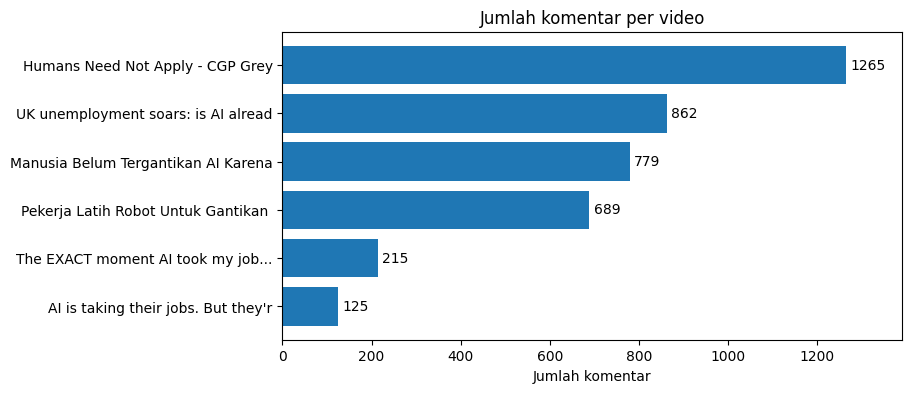

In [70]:
v = df_EDA["video_title"].value_counts().sort_values()

plt.figure(figsize=(8, 4))
batang = plt.barh(v.index.str[:35], v.values)
plt.bar_label(batang, padding=3)          # angka di ujung batang
plt.xlim(0, v.max() * 1.1)                # beri ruang supaya angka tidak terpotong
plt.title("Jumlah komentar per video")
plt.xlabel("Jumlah komentar")
plt.show()

**Hasil:**

| Video | Bahasa | Komentar | Persen |
|---|---|---|---|
| Humans Need Not Apply - CGP Grey | Inggris | 1.265 | 32,1% |
| UK unemployment soars: is AI already taking our jobs? | Inggris | 862 | 21,9% |
| Manusia Belum Tergantikan AI Karena Satu Hambatan Ini | Indonesia | 779 | 19,8% |
| Pekerja Latih Robot Untuk Gantikan Mereka! | Indonesia | 689 | 17,5% |
| The EXACT moment AI took my job... | Inggris | 215 | 5,5% |
| AI is taking their jobs. But they're fighting back. | Inggris | 125 | 3,2% |

Jumlah komentar antarvideo **tidak seimbang**: video terbanyak (1.265) sekitar 10 kali video tersedikit (125), dan tiga video teratas menyumbang hampir tiga perempat data. Karena itu perbandingan antarvideo sebaiknya memakai persentase, bukan jumlah mentah.

## **4.2 Komposisi Bahasa**

**Pertanyaan:** berapa banyak komentar berbahasa Indonesia dan Inggris?

**Grafik:** jumlah komentar per bahasa dalam diagram batang.

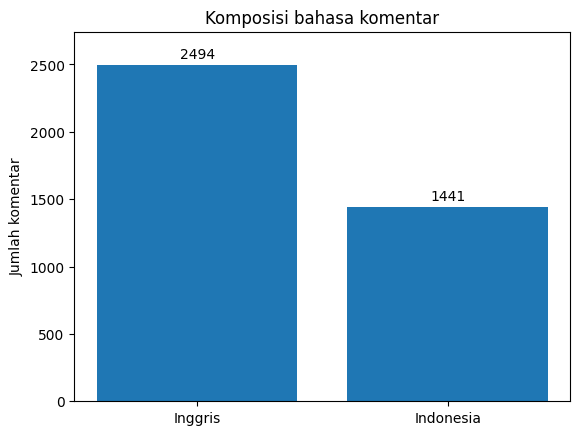

In [71]:
b = df_EDA["bahasa"].value_counts()

batang = plt.bar(b.index, b.values)
plt.bar_label(batang, padding=3)       # angka di atas batang
plt.ylim(0, b.max() * 1.1)             # beri ruang supaya angka tidak terpotong
plt.title("Komposisi bahasa komentar")
plt.ylabel("Jumlah komentar")
plt.show()

**Hasil:** komentar berbahasa Inggris berjumlah **2.494 (63,4%)** dan berbahasa Indonesia **1.441 (36,6%)**. Perbandingan ini sejalan dengan jumlah video: empat video berbahasa Inggris dan dua video berbahasa Indonesia.

## **4.3 Bahasa per Video**

**Pertanyaan:** apakah bahasa komentar mengikuti bahasa videonya?

**Grafik:** persentase bahasa di setiap video (setiap video dihitung 100%) dalam batang bertumpuk.

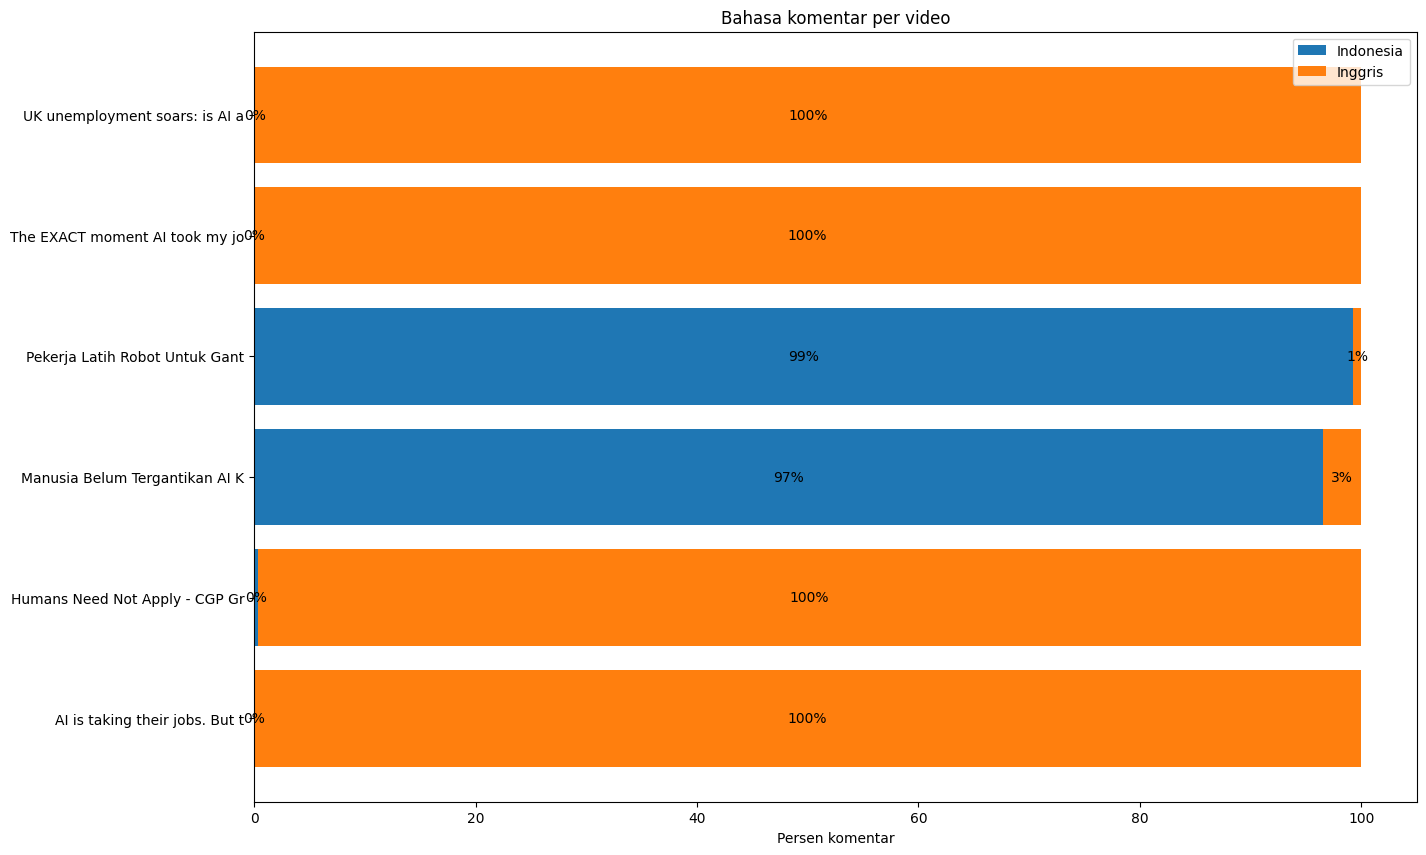

In [72]:
tabel = pd.crosstab(df_EDA["video_title"].str[:30], df_EDA["bahasa"])
persen = tabel.div(tabel.sum(axis=1), axis=0) * 100     # tiap video jadi 100%

kiri = 0
plt.figure(figsize=(15, 10))
for kolom in persen.columns:
    batang = plt.barh(persen.index, persen[kolom], left=kiri, label=kolom)
    plt.bar_label(batang, fmt="%.0f%%", label_type="center")
    kiri = kiri + persen[kolom]
plt.legend()
plt.xlabel("Persen komentar")
plt.title("Bahasa komentar per video")
plt.show()

**Hasil:** bahasa komentar hampir sepenuhnya mengikuti bahasa video. Dua video berbahasa Indonesia berisi 96,5% (*Manusia Belum Tergantikan*) dan 99,3% (*Pekerja Latih Robot*) komentar Indonesia, sedangkan keempat video berbahasa Inggris berisi 99,7% sampai 100% komentar Inggris. Hanya sebagian kecil penonton video Indonesia yang menulis dalam bahasa Inggris.

## **4.4 Panjang Komentar**

**Pertanyaan:** seberapa panjang komentar yang akan dilabeli?

**Grafik:** histogram jumlah kata per komentar. Komentar yang lebih dari 100 kata dihitung sebagai 100 supaya grafik tetap terbaca.

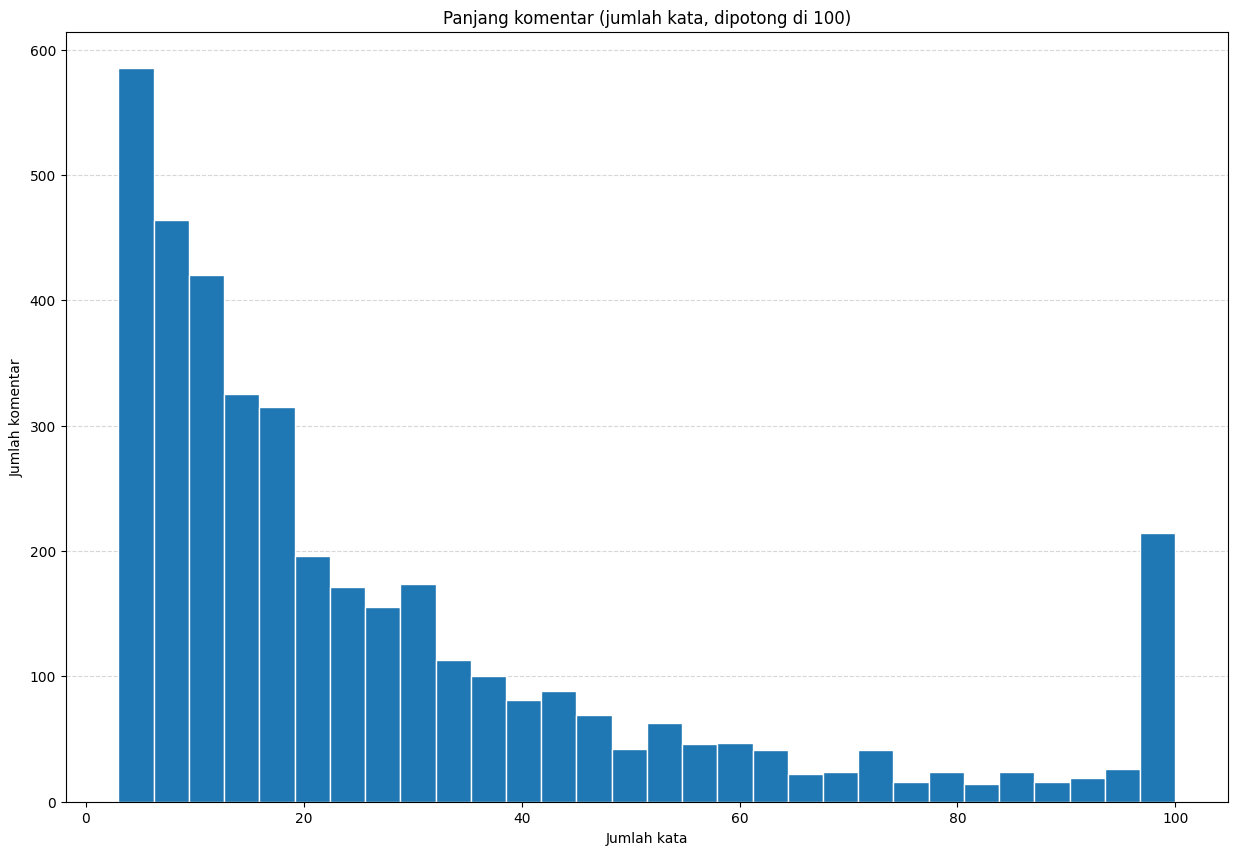

In [73]:
kata = df_EDA["comment"].str.split().str.len().clip(upper=100)

plt.figure(figsize=(15, 10))
plt.hist(kata, bins=30, edgecolor="white")
plt.grid(axis="y", linestyle="--", alpha=0.5)   # garis bantu mendatar
plt.gca().set_axisbelow(True)                   # garis di belakang batang
plt.title("Panjang komentar (jumlah kata, dipotong di 100)")
plt.xlabel("Jumlah kata")
plt.ylabel("Jumlah komentar")
plt.show()

**Hasil:** sebagian besar komentar pendek. Nilai tengahnya 17 kata, rata-rata 30,6 kata, dan 95% komentar paling banyak 100 kata. Komentar terpendek 3 kata (sesuai batas di 3.7) dan terpanjang 501 kata. Batang di angka 100 adalah gabungan komentar yang lebih dari 100 kata (sekitar 5%).

## **4.5 Emoji dan Tanda Baca**

**Pertanyaan:** seberapa sering komentar memakai emoji dan tanda `?` atau `!`? Keduanya sering menandai emosi atau pertanyaan, dan karena itu sengaja tidak dibuang saat pembersihan teks (3.4).

**Grafik:** jumlah komentar yang memuat emoji dan jumlah komentar yang memuat tanda `?` atau `!`.

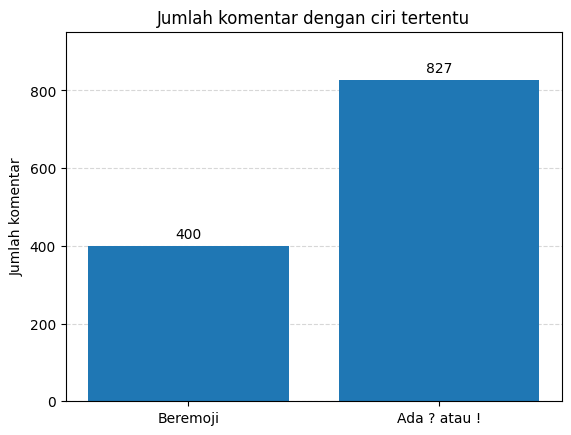

In [74]:
emoji = df_EDA["comment"].str.contains("[\U0001F300-\U0001FAFF\u2600-\u27BF]").sum()
tanda = df_EDA["comment"].str.contains(r"[?!]").sum()

batang = plt.bar(["Beremoji", "Ada ? atau !"], [emoji, tanda])
plt.bar_label(batang, padding=3)
plt.ylim(0, max(emoji, tanda) * 1.15)
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.gca().set_axisbelow(True)
plt.title("Jumlah komentar dengan ciri tertentu")
plt.ylabel("Jumlah komentar")
plt.show()

**Hasil:** **400 komentar (10,2%)** memakai emoji dan **827 komentar (21,0%)** memakai tanda `?` atau `!`. Artinya sekitar seperlima komentar berbentuk pertanyaan atau seruan, sehingga keputusan mempertahankan tanda baca dan emoji membantu pelabel membaca nada komentar.

## **4.6 Sebaran Likes per Komentar**

**Pertanyaan:** bagaimana sebaran jumlah *like* per komentar?

*Like* menunjukkan seberapa banyak penonton setuju dengan sebuah komentar. Sebarannya sangat miring, jadi jumlah *like* dikelompokkan (0, 1–10, 11–100, 101–1.000, dan lebih dari 1.000) supaya grafik tetap terbaca.

**Catatan:** komentar diambil dengan urutan "terpopuler", sehingga komentar yang banyak di-*like* lebih terwakili daripada keadaan sebenarnya.

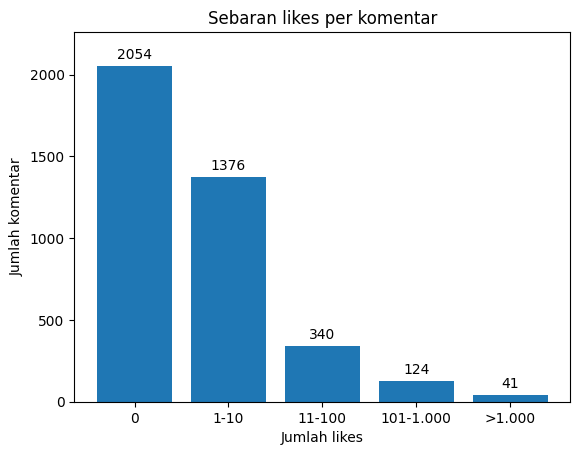

In [75]:
kelompok = pd.cut(df_EDA["likes"], bins=[-1, 0, 10, 100, 1000, float("inf")],
                  labels=["0", "1-10", "11-100", "101-1.000", ">1.000"])
k = kelompok.value_counts().sort_index()

batang = plt.bar(k.index, k.values)
plt.bar_label(batang, padding=3)
plt.ylim(0, k.max() * 1.1)
plt.title("Sebaran likes per komentar")
plt.xlabel("Jumlah likes")
plt.ylabel("Jumlah komentar")
plt.show()

**Hasil:** Lebih dari separuh komentar (52%) tidak mendapat like sama sekali, dan 87% mendapat paling banyak 10 like. Hanya 41 komentar (1%) yang mendapat lebih dari 1.000 like. Artinya, persetujuan penonton terkumpul pada segelintir komentar.

## **4.7 Komentar yang Mendapat Like per Video**

**Pertanyaan:** di video mana komentar paling sering mendapat *like*?

Median *like* hampir selalu 0, jadi yang dibandingkan adalah persentase komentar yang mendapat minimal 1 *like* di setiap video.

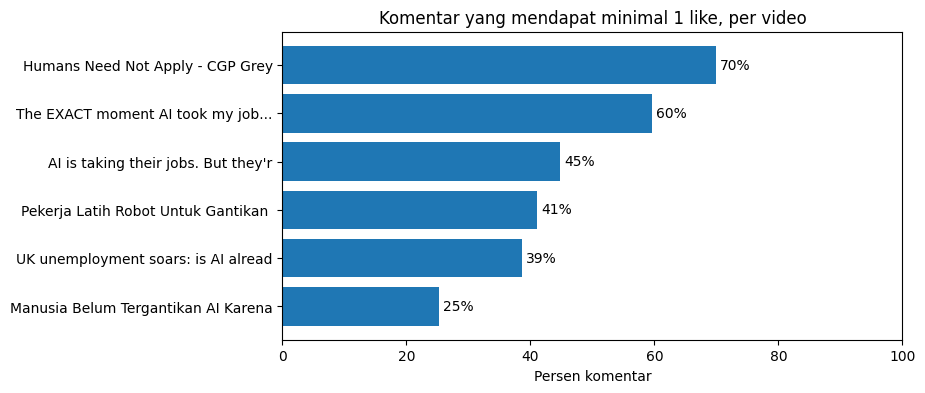

In [76]:
# 1. Tandai komentar yang mendapat minimal 1 like
dapat_like = df_EDA["likes"] > 0

# 2. Hitung persentasenya untuk setiap video
persen = dapat_like.groupby(df_EDA["video_title"]).mean() * 100
persen = persen.sort_values()

plt.figure(figsize=(8, 4))
batang = plt.barh(persen.index.str[:35], persen.values)
plt.bar_label(batang, fmt="%.0f%%", padding=3)
plt.xlim(0, 100)
plt.title("Komentar yang mendapat minimal 1 like, per video")
plt.xlabel("Persen komentar")
plt.show()

**Hasil:** komentar di video *Humans Need Not Apply* (CGP Grey) paling sering mendapat *like* (70%), disusul *The EXACT moment* (60%), sedangkan *Manusia Belum Tergantikan AI* paling jarang (25%). Angka ini juga dipengaruhi popularitas video, bukan hanya isi komentarnya.

## **4.8 Komentar yang Mendapat Like per Bahasa**

**Pertanyaan:** apakah komentar berbahasa Inggris lebih sering mendapat *like* daripada komentar berbahasa Indonesia?

**Grafik:** persentase komentar yang mendapat minimal 1 *like* untuk setiap bahasa.

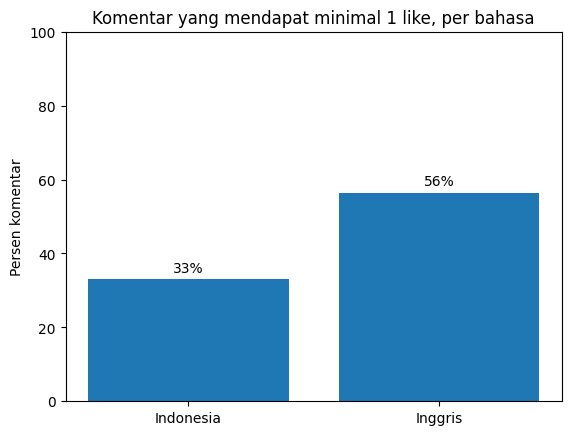

In [77]:
# 1. Tandai komentar yang mendapat minimal 1 like
dapat_like = df_EDA["likes"] > 0

# 2. Hitung persentasenya untuk setiap bahasa
persen = dapat_like.groupby(df_EDA["bahasa"]).mean() * 100

batang = plt.bar(persen.index, persen.values)
plt.bar_label(batang, fmt="%.0f%%", padding=3)
plt.ylim(0, 100)
plt.title("Komentar yang mendapat minimal 1 like, per bahasa")
plt.ylabel("Persen komentar")
plt.show()

**Hasil:** Komentar bahasa Inggris lebih sering mendapat like (56%) dibanding bahasa Indonesia (33%). Sebagian besar komentar bahasa Inggris berasal dari video internasional yang jauh lebih populer, jadi perbedaan ini lebih mencerminkan jumlah penonton daripada bahasanya.

## **4.9 Sepuluh Komentar dengan Like Terbanyak**

**Pertanyaan:** komentar apa yang paling banyak disukai penonton?

**Tabel:** 10 komentar dengan *like* terbanyak beserta judul video dan bahasanya.

In [78]:
df_EDA.nlargest(10, "likes")[["comment", "likes", "video_title", "bahasa"]]

,comment,likes,video_title,bahasa
1478,"""you might think technology can't replace your job"" I'd be pretty horrified if technology started replacing unemployed peoples jobs.",31000,Humans Need Not Apply - CGP Grey,Inggris
1471,Aged like fine wine,30000,Humans Need Not Apply - CGP Grey,Inggris
1871,I'd really like an updated version of this video.,26000,Humans Need Not Apply - CGP Grey,Inggris
1482,"""The human brain is the most complicated machine, perhaps in the whole universe."" - Human Brain",24000,Humans Need Not Apply - CGP Grey,Inggris
1873,"So you think a bot can take my job? The joke's on you, I don't have a job!",19000,Humans Need Not Apply - CGP Grey,Inggris
1474,"This was 8 years ago, now with the sudden rise of AI music, AI art, AI video, ChatGPT, and so on... that's crazy...",14000,Humans Need Not Apply - CGP Grey,Inggris
1884,New goal: Make it to retirement without being replaced,14000,Humans Need Not Apply - CGP Grey,Inggris
1470,This wouldn't be scary if we lived in a world where being unemployed didn't mean loss of livelihood,13000,Humans Need Not Apply - CGP Grey,Inggris
1468,I was thinking this video was getting out of date… then AI art and language models arrived and I am more concerned about this topic than...,11000,Humans Need Not Apply - CGP Grey,Inggris
1487,"Those darn automation engineers, taking over everyone's jobs. At least I'm safe looks at degree in robotics ... looks at robots that tea...",9800,Humans Need Not Apply - CGP Grey,Inggris


**Hasil:** kesepuluh komentar teratas semuanya berasal dari video CGP Grey (bahasa Inggris), dengan 9.800 sampai 31.000 *like*. Isinya campuran candaan, misalnya "So you think a bot can take my job? The joke's on you, I don't have a job!", dan kekhawatiran soal pekerjaan yang digantikan teknologi, misalnya "New goal: Make it to retirement without being replaced" (14.000 *like*).

### **Ringkasan EDA**

| Temuan | Artinya untuk tahap berikutnya |
|---|---|
| Jumlah komentar antarvideo tidak seimbang (125 sampai 1.265) | Perbandingan antarvideo dibaca sebagai persentase |
| Inggris 63,4%, Indonesia 36,6%, dan bahasa komentar mengikuti bahasa video | Pelabel harus memahami kedua bahasa |
| Nilai tengah panjang komentar 17 kata, 95% paling banyak 100 kata | Komentar umumnya pendek dan bisa dibaca utuh saat dilabeli |
| 10% komentar memakai emoji dan 21% memakai `?` atau `!` | Emoji dan tanda baca dipertahankan karena membawa nada komentar |
| 52% komentar tanpa *like*, dan *like* terkumpul pada segelintir komentar video CGP Grey | *Like* tidak dipakai sebagai fitur klasifikasi, hanya sebagai gambaran |

# **5. Pelabelan (Labeling)**

Komentar bersih dari Bab 3 (**3.935 komentar**) diberi satu dari tiga label: **positif**, **negatif**, atau **perlu ditinjau**. Pelabelan dikerjakan gabungan **manusia** dan **Claude Opus 5.5** (model AI buatan Anthropic) lewat sesi chat, **bukan lewat kode di notebook ini**. Karena itu bab ini sebagian besar berisi penjelasan; kode hanya dipakai untuk **menguji kualitas label** (Bab 5.3) dan **mencari pola sikap** (Bab 5.5). Hasilnya disimpan sebagai `youtube_comments_label_final.csv` di folder `datasets`.

## **5.1 Panduan Pelabelan**

Yang dinilai adalah **sikap penulis terhadap AI dan pekerjaan**, bukan pendapat pelabel dan bukan gaya bahasanya.

| Label | Aturan |
|---|---|
| **positif** | Condong tidak takut, optimis, atau mendukung. Termasuk: AI cuma alat; AI masih sering salah, *overhyped*, atau tidak bisa menggantikan manusia; ajakan belajar/adaptasi dengan nada optimis; menyalahkan pajak, ekonomi, pemerintah, atau *offshoring* (bukan AI) atas hilangnya pekerjaan. |
| **negatif** | Condong takut, khawatir, pesimis, menolak, atau menyalahkan AI. Termasuk: keluhan kehilangan pekerjaan/klien karena AI; prediksi pesimis soal pekerjaan; AI harus dilarang atau dibatasi; AI berbahaya; muak pada perusahaan yang mengganti pekerja dengan AI. |
| **perlu ditinjau** | Hanya untuk yang **benar-benar ambigu**: tidak membahas AI atau pekerjaan (*off-topic*), pertanyaan netral murni, ucapan terima kasih atau pujian video, dan sindiran/candaan yang arahnya tidak jelas. |

**Mengapa "perlu ditinjau", bukan "netral"?** Pada rancangan awal dipakai label **netral** dan **tidak relevan**. Saat pelabelan ternyata banyak komentar berupa **sindiran atau candaan yang sikapnya tersirat**: komentar seperti ini sebenarnya punya sikap, tetapi arahnya sulit dipastikan, sehingga tidak tepat disebut netral. Selain itu, batas antara netral dan tidak relevan sering tidak konsisten. Karena itu keduanya digabung menjadi **perlu ditinjau**, yaitu komentar yang sikapnya tidak bisa dipastikan dan **layak ditinjau ulang oleh manusia**. Bab 5.5 dan Bab 6.1 notebook klasifikasi menunjukkan bahwa komentar dengan *likes* terbanyak justru didominasi label ini.

**Arti label positif.** "Positif" di sini berarti **tidak memandang AI sebagai ancaman bagi pekerjaan**, bukan berarti senang. Karena itu komentar yang menyalahkan pajak atau ekonomi (bukan AI) atas hilangnya pekerjaan juga dilabeli positif.

**Pohon keputusan** (dijawab berurutan):
1. Apakah komentar membahas AI, pekerjaan, atau dampak AI? Tidak → **perlu ditinjau**.
2. Condong takut, khawatir, pesimis, menolak, atau menyalahkan AI? Ya → **negatif**.
3. Condong tidak takut, optimis, mendukung, atau menyalahkan faktor lain selain AI? Ya → **positif**.
4. Arahnya benar-benar tidak bisa ditentukan → **perlu ditinjau**.

**Contoh:**

| Komentar | Label |
|---|---|
| *"AI cuma alat, yang penting kita terus belajar"* | positif |
| *"PHK sekarang karena pajak naik, bukan karena AI"* | positif |
| *"Takut banget kerjaan gue diambil AI"* | negatif |
| *"Nanti 50% pekerjaan hilang karena AI"* | negatif |
| *"Siapa yang beli barang kalau semua diganti AI?"* | negatif |
| *"Terima kasih bang videonya"* | perlu ditinjau |
| *"Bahas imigran Maroko dong bang"* | perlu ditinjau |

**Panduan awal dan panduan akhir.** Panduan di atas adalah **versi akhir** (dipakai untuk label Claude v8). Pelabel manusia memakai **versi awal** yang tersimpan di sheet *Panduan* pada `datasets/label_manual_300.xlsx`. Strukturnya sama (pohon keputusan, aturan kasus abu-abu, dan contoh patokan). Perbedaan yang paling jelas:

| Hal | Panduan awal (pelabel manusia) | Panduan akhir (Claude v8) |
|---|---|---|
| Langkah 1 pohon keputusan | membahas AI dan pekerjaan | membahas AI, pekerjaan, **atau dampak AI** |
| *"Siapa yang beli kalau semua diganti AI?"* | perlu ditinjau | **negatif** (pesimis soal dampak AI pada ekonomi) |

Perbedaan ini ikut menjelaskan sebagian ketidakcocokan label Claude dengan manusia di Bab 5.3, yaitu komentar yang dinilai manusia perlu ditinjau tetapi diberi negatif oleh Claude.


## **5.2 Cara Pelabelan**

| Tahap | Pelabel | Jumlah komentar |
|---|---|---|
| 1. Gold set | manual (manusia) | 150 |
| 2. Sampel acak | manual: pelabel 1 (200 komentar) dan pelabel 2 (99 komentar) | 299 |
| 3. Sisa komentar | Claude Opus 5.5 | 3.486 |
| **Total** | | **3.935** |

1. **Label manual (449 komentar).** Gold set (150 komentar) dilabeli manual lebih dulu. Gold set awalnya memakai 4 label, sehingga label netral dan tidak relevan digabung menjadi **perlu ditinjau**. Lalu 300 komentar diambil secara acak dan dilabeli manual oleh dua anggota tim (disebut pelabel 1 dan pelabel 2) lewat lembar Excel berisi panduan dan pilihan label; satu komentar dibuang karena isinya hanya tautan, sehingga tersisa 299.
2. **Label Claude (3.486 komentar).** Sisa komentar dilabeli Claude Opus 5.5 dengan panduan 5.1. Sebagai contoh patokan, Claude diberi **200 label manual pelabel 1**, supaya cara menilainya mengikuti cara manusia. Komentar dikerjakan per kelompok 150 komentar, dan setiap komentar harus mendapat tepat satu label yang sah.
**Mengapa sebagian besar label dibuat dengan bantuan LLM?** Melabeli 3.935 komentar secara manual oleh tim kecil membutuhkan waktu yang lama. Untuk **efisiensi**, sebagian kecil komentar (449) dilabeli manual, lalu sisanya (3.486) dilabeli dengan **LLM** (*large language model*). Pendekatan ini makin umum dipakai untuk anotasi teks, dengan syarat **kualitasnya diuji** terhadap label manusia. Pengujian itu dilakukan secara buta di Bab 5.3.

**Pemilihan LLM.** Uji coba awal memakai **Qwen** lewat API, tetapi dihentikan karena **batasan akses API** (jumlah permintaan dibatasi). Pelabelan kemudian dilanjutkan dengan **Claude Opus 5.5** melalui **antarmuka chat**, sehingga prosesnya tidak berupa kode di notebook ini.

**Perbaikan panduan bertahap.** Panduan untuk Claude diperbaiki beberapa kali (versi v1 sampai v8) supaya aturan pada kasus abu-abu makin jelas. Setiap versi diuji terhadap 99 label manusia, dan **versi akhir dipilih berdasarkan kecocokan tertinggi dengan label manusia** (Bab 5.3), bukan berdasarkan skor model klasifikasi.

3. **Digabung.** Untuk 449 komentar berlabel manual, **label manusia yang dipakai**. Asal setiap label dicatat di kolom `sumber_label`: `manual` (449) atau `claude` (3.486).

## **5.3 Uji Kualitas Label**

Label pelabel 2 (99 komentar) **tidak pernah dijadikan contoh** untuk Claude. Komentar yang sama juga dilabeli Claude, lalu hasilnya dibandingkan dengan label manusia untuk mengukur seberapa mirip cara Claude menilai dengan cara manusia. Label akhir 99 komentar ini tetap memakai label manusia.

Tiga ukuran yang dipakai:
- **Macro-F1**: rata-rata F1 ketiga label, setiap label dianggap sama penting.
- **Akurasi**: persentase komentar yang labelnya sama.
- **Cohen's kappa**: kesepakatan setelah dikurangi kesepakatan yang terjadi karena kebetulan (0 = asal tebak, 1 = sempurna; 0,41-0,60 = sedang).

**Sel ini:** memuat 299 label manual dan label Claude versi akhir (v8) dari GitHub, lalu mengambil 99 komentar pelabel 2.

In [79]:
url_dataset = "https://raw.githubusercontent.com/RoihansLab/Data-Mining-Project/main/datasets/"

# 1. Label manual 299 komentar, ambil hanya milik pelabel 2 (data uji buta)
label_manual = pd.read_csv(url_dataset + "label_manual_299.csv")
uji_buta = label_manual[label_manual["pelabel"] == "pelabel 2"][["comment", "label"]]
uji_buta = uji_buta.rename(columns={"label": "label_manusia"})

# 2. Label Claude versi akhir (v8) untuk komentar yang sama
label_v8 = pd.read_csv(url_dataset + "youtube_comments_label_claude_v8.csv")
label_v8 = label_v8[["comment", "label_v8"]].rename(columns={"label_v8": "label_claude"})
uji_buta = uji_buta.merge(label_v8, on="comment")

print("Jumlah komentar uji buta:", len(uji_buta))
uji_buta.head()

Jumlah komentar uji buta: 99


,comment,label_manusia,label_claude
0,Menurutku di masa depan orang miskin - menengah kebawah makin gaada atau setidaknya hampir hilang lalu gapnya dengan yg kelas atas bakal...,negatif,negatif
1,You workED for an AI based startup... do you think that really represents the majority of jobs? lol no wonder they fired you,perlu ditinjau,perlu ditinjau
2,"It’s all rubbish,",perlu ditinjau,perlu ditinjau
3,"Same, last Friday. Replaced by AI. Good luck!",negatif,negatif
4,Agak bingung juga tuh bisnis seperti itu kek anthropic dan sebagai nya...pengangguran tidak mungkin pakai AI. Masa depan Teknologi nya i...,perlu ditinjau,negatif


**Sel ini:** menghitung macro-F1, akurasi, dan kappa label Claude terhadap label manusia, lalu menampilkan tabel silang (baris = label manusia, kolom = label Claude).

In [80]:
print("Macro-F1:", round(f1_score(uji_buta["label_manusia"], uji_buta["label_claude"], average="macro"), 3))
print("Akurasi :", round(accuracy_score(uji_buta["label_manusia"], uji_buta["label_claude"]), 3))
print("Kappa   :", round(cohen_kappa_score(uji_buta["label_manusia"], uji_buta["label_claude"]), 3))

pd.crosstab(uji_buta["label_manusia"], uji_buta["label_claude"])

Macro-F1: 0.676
Akurasi : 0.707
Kappa   : 0.506


label_claude,negatif,perlu ditinjau,positif
label_manusia,,,
negatif,15,3,0
perlu ditinjau,13,43,7
positif,3,3,12


**Perbandingan versi label Claude.** Panduan pelabelan diperbaiki beberapa kali sampai versi akhir (v8). Versi akhir dipilih berdasarkan **kecocokan dengan label manusia** pada 99 komentar uji buta, bukan berdasarkan skor model klasifikasi (supaya label tidak dipilih demi membuat model terlihat bagus).

- Versi 1-3 masih memakai 4 label (positif, negatif, netral, tidak relevan), sehingga **netral dan tidak relevan digabung menjadi perlu ditinjau** supaya bisa dibandingkan.
- Versi 4 dan 5 tidak tersimpan, sehingga tidak ikut dibandingkan.

**Sel ini:** menghitung macro-F1 dan kappa setiap versi yang tersimpan, lalu menggambarnya sebagai grafik garis.

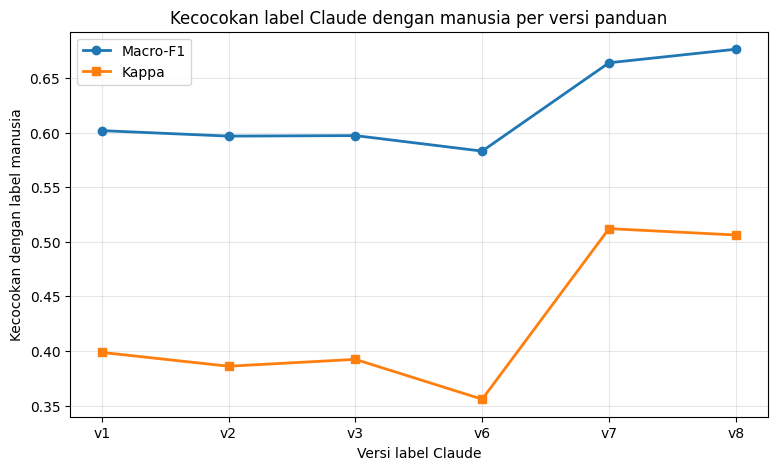

,Versi,Jumlah komentar,Macro-F1,Kappa
0,v1,96,0.602,0.399
1,v2,96,0.597,0.386
2,v3,99,0.597,0.392
3,v6,99,0.583,0.356
4,v7,99,0.664,0.512
5,v8,99,0.676,0.506


In [81]:
# Nama file dan nama kolom label setiap versi
versi_label = {
    "v1": ["youtube_comments_label_claude.csv", "label"],
    "v2": ["youtube_comments_label_claude_v2.csv", "label"],
    "v3": ["youtube_comments_label_claude_v3.csv", "label"],
    "v6": ["youtube_comments_label_claude_v6.csv", "label_v6"],
    "v7": ["youtube_comments_label_claude_v7.csv", "label_v7"],
    "v8": ["youtube_comments_label_claude_v8.csv", "label_v8"],
}
gabung_label = {"netral": "perlu ditinjau", "tidak relevan": "perlu ditinjau"}

hasil_versi = []
for versi, (nama_file, kolom) in versi_label.items():
    # 1. Ambil label Claude versi ini untuk 99 komentar uji buta
    d = pd.read_csv(url_dataset + nama_file)[["comment", kolom]].drop_duplicates("comment")
    d = d.merge(uji_buta[["comment", "label_manusia"]], on="comment")

    # 2. Samakan label lama (4 label) menjadi 3 label
    label_claude = d[kolom].replace(gabung_label)

    # 3. Hitung kecocokan dengan label manusia
    hasil_versi.append({
        "Versi": versi,
        "Jumlah komentar": len(d),
        "Macro-F1": f1_score(d["label_manusia"], label_claude, average="macro"),
        "Kappa": cohen_kappa_score(d["label_manusia"], label_claude),
    })

hasil_versi = pd.DataFrame(hasil_versi)

plt.figure(figsize=(9, 5))
plt.plot(hasil_versi["Versi"], hasil_versi["Macro-F1"], "o-", linewidth=2, label="Macro-F1")
plt.plot(hasil_versi["Versi"], hasil_versi["Kappa"], "s-", linewidth=2, label="Kappa")
plt.xlabel("Versi label Claude")
plt.ylabel("Kecocokan dengan label manusia")
plt.title("Kecocokan label Claude dengan manusia per versi panduan")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

hasil_versi.round(3)

**Hasil:**

| Dibandingkan dengan 99 label pelabel 2 | Macro-F1 | Akurasi | Kappa |
|---|---|---|---|
| Label Claude Opus 5.5 (v8) | 0,676 | 0,707 | 0,506 |

- **Kappa 0,506** berarti kesepakatan **sedang**: Claude dan manusia sering sepakat, tetapi masih berbeda di kasus abu-abu.
- Dari 29 komentar yang berbeda, 13 komentar dinilai manusia **perlu ditinjau** tetapi diberi **negatif** oleh Claude, dan 7 komentar diberi **positif**. Artinya, Claude lebih cepat menangkap nada condong pada komentar soal pekerjaan, sedangkan manusia lebih sering memilih perlu ditinjau. Batas ini memang sulit, bahkan bagi manusia.
- Kecocokan label ini menjadi **batas atas yang realistis** bagi model klasifikasi: model tidak bisa jauh lebih akurat daripada labelnya sendiri.

**Perbandingan versi:**

| Versi | Label | Komentar | Macro-F1 | Kappa |
|---|---|---|---|---|
| v1 | 4 label | 96 | 0,602 | 0,399 |
| v2 | 4 label | 96 | 0,597 | 0,386 |
| v3 | 4 label | 99 | 0,597 | 0,392 |
| v6 | 3 label | 99 | 0,583 | 0,356 |
| v7 | 3 label | 99 | 0,664 | **0,512** |
| **v8 (dipakai)** | 3 label | 99 | **0,676** | 0,506 |

- Kecocokan dengan manusia **naik dari kappa sekitar 0,39 (v1-v3) menjadi sekitar 0,51 (v7-v8)** setelah panduan dipertegas: sindiran yang arahnya jelas dimasukkan ke negatif atau positif, dan "perlu ditinjau" hanya untuk yang benar-benar ambigu.
- v1 dan v2 hanya mencakup 96 komentar, karena saat itu data bersihnya sedikit berbeda (3.929 komentar).
- **v8 dipilih** karena macro-F1-nya paling tinggi (0,676), dengan kappa hampir sama dengan v7 (0,506 vs 0,512).

## **5.4 Sebaran Label**

| Label | Jumlah | Persentase |
|---|---|---|
| perlu ditinjau | 2.342 | 59,5% |
| negatif | 938 | 23,8% |
| positif | 655 | 16,6% |
| **Total** | **3.935** | 100% |

- Lebih dari separuh komentar (59,5%) **perlu ditinjau**, karena banyak komentar YouTube berupa candaan, debat yang melebar, permintaan konten, atau *off-topic*.
- Di antara **1.593 komentar yang punya sikap jelas**, **negatif lebih banyak (58,9%)** daripada positif (41,1%). Artinya, publik yang bersikap terhadap isu ini lebih banyak yang **khawatir atau menolak** AI yang menggantikan pekerjaan.
- Labelnya **tidak seimbang**, sehingga tahap klasifikasi memakai pembobotan label (`class_weight="balanced"`) dan dinilai dengan **macro-F1**, bukan akurasi saja.

## **5.5 Pola Sikap Publik**

Grafik di Bab 4 dibuat **sebelum** komentar punya label, jadi belum bisa menunjukkan pola sikap. Bagian ini memakai data yang **sudah berlabel** untuk mencari pola yang tidak terlihat dari jumlah label saja:

| Visualisasi | Bentuk | Pertanyaan |
|---|---|---|
| Sikap per video | *heatmap* | video mana yang komentarnya paling khawatir, paling optimis, atau paling banyak candaan? |
| Sikap vs panjang komentar | grafik garis | apakah komentar yang lebih panjang lebih sering punya sikap jelas? |
| *Likes* per sikap | *box plot* | sikap mana yang paling disukai penonton? |

**Sel ini:** memuat data berlabel final langsung dari GitHub.

In [82]:
url_label = "https://raw.githubusercontent.com/RoihansLab/Data-Mining-Project/main/datasets/youtube_comments_label_final.csv"

df_label = pd.read_csv(url_label)
df_label["label"].value_counts()

,count
label,
perlu ditinjau,2342
negatif,938
positif,655


**Grafik 1: sikap per video (*heatmap*).** Setiap baris adalah satu video dan jumlahnya 100%. Warna makin gelap berarti persentasenya makin besar.

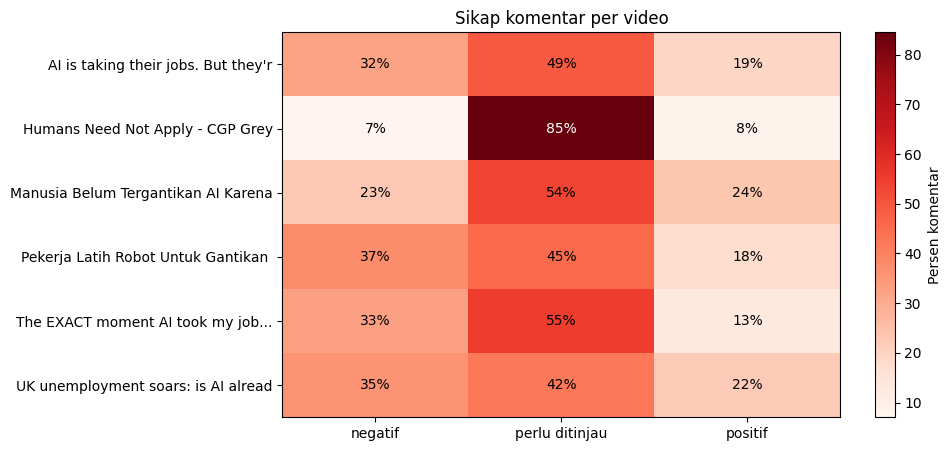

In [83]:
# Persentase setiap label di setiap video (setiap baris = 100%)
label_per_video = pd.crosstab(df_label["video_title"].str[:35], df_label["label"], normalize="index") * 100

fig, ax = plt.subplots(figsize=(9, 5))
gambar = ax.imshow(label_per_video.values, cmap="Reds", aspect="auto")
ax.set_xticks(range(len(label_per_video.columns)), label_per_video.columns)
ax.set_yticks(range(len(label_per_video.index)), label_per_video.index)

# Tulis persentase di setiap kotak
for i in range(len(label_per_video.index)):
    for j in range(len(label_per_video.columns)):
        nilai = label_per_video.values[i, j]
        warna = "white" if nilai > 60 else "black"   # tulisan putih di kotak yang gelap
        ax.text(j, i, f"{nilai:.0f}%", ha="center", va="center", color=warna)

plt.colorbar(gambar, label="Persen komentar")
plt.title("Sikap komentar per video")
plt.show()

**Grafik 2: sikap vs panjang komentar (grafik garis).** Komentar dikelompokkan menurut jumlah katanya, lalu dihitung persentase setiap label di setiap kelompok. Garis menunjukkan **arah perubahan** saat komentar makin panjang.

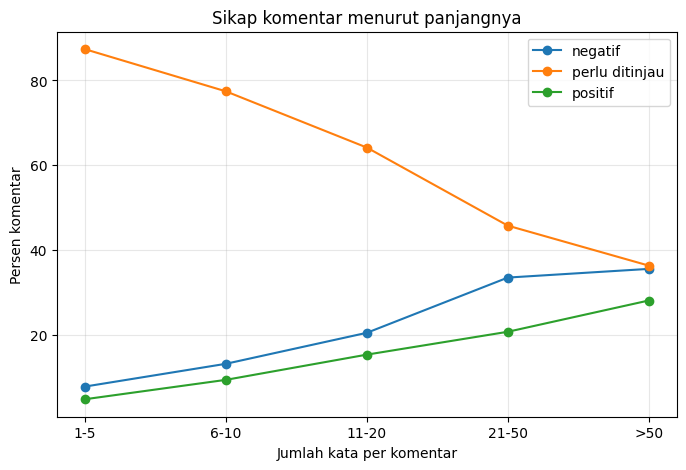

label,negatif,perlu ditinjau,positif
comment,,,
1-5,7.8,87.4,4.8
6-10,13.2,77.4,9.4
11-20,20.5,64.2,15.3
21-50,33.5,45.8,20.7
>50,35.6,36.3,28.1


In [84]:
# 1. Hitung jumlah kata setiap komentar, lalu kelompokkan
jumlah_kata = df_label["comment"].str.split().str.len()
kelompok_panjang = pd.cut(jumlah_kata, bins=[0, 5, 10, 20, 50, 1000], labels=["1-5", "6-10", "11-20", "21-50", ">50"])

# 2. Persentase setiap label di setiap kelompok panjang (setiap kelompok = 100%)
label_per_panjang = pd.crosstab(kelompok_panjang, df_label["label"], normalize="index") * 100

plt.figure(figsize=(8, 5))
for nama_label in label_per_panjang.columns:
    plt.plot(label_per_panjang.index.astype(str), label_per_panjang[nama_label], "o-", label=nama_label)
plt.xlabel("Jumlah kata per komentar")
plt.ylabel("Persen komentar")
plt.title("Sikap komentar menurut panjangnya")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

label_per_panjang.round(1)

**Grafik 3: *likes* per sikap (*box plot*).** Kotak menunjukkan sebaran *likes* untuk setiap label: garis tengah adalah median, dan titik-titik di atas adalah komentar yang *likes*-nya jauh lebih banyak dari biasanya. Sumbu *likes* memakai skala log (dan ditambah 1, supaya komentar dengan 0 *like* tetap bisa digambar), karena *likes* sangat timpang (Bab 4.6).

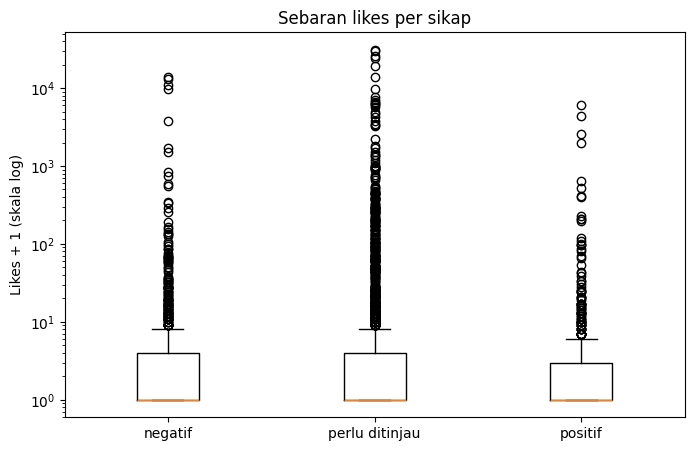

In [85]:
# Kumpulkan likes (+1) untuk setiap label
daftar_label = ["negatif", "perlu ditinjau", "positif"]
likes_per_label = []
for nama_label in daftar_label:
    likes_per_label.append(df_label.loc[df_label["label"] == nama_label, "likes"] + 1)

plt.figure(figsize=(8, 5))
plt.boxplot(likes_per_label)
plt.xticks([1, 2, 3], daftar_label)
plt.yscale("log")
plt.ylabel("Likes + 1 (skala log)")
plt.title("Sebaran likes per sikap")
plt.show()

**Sel ini:** melihat sikap dari **50 komentar dengan *likes* terbanyak**.

In [86]:
df_label.nlargest(50, "likes")["label"].value_counts()

,count
label,
perlu ditinjau,38
negatif,8
positif,4


**Hasil:**

**1. Sikap per video**

| Video | Negatif | Perlu ditinjau | Positif |
|---|---|---|---|
| Pekerja Latih Robot Untuk Gantikan Mereka! | **37,0%** | 45,4% | 17,6% |
| UK unemployment soars: is AI already taking our jobs? | 35,5% | 42,2% | 22,3% |
| The EXACT moment AI took my job... | 32,6% | 54,9% | 12,6% |
| AI is taking their jobs. But they're fighting back. | 32,0% | 48,8% | 19,2% |
| Manusia Belum Tergantikan AI Karena Satu Hambatan Ini | 22,8% | 53,5% | **23,6%** |
| Humans Need Not Apply - CGP Grey | 7,0% | **84,5%** | 8,5% |

- **Judul video ikut memengaruhi sikap penonton.** Video dengan judul yang menakutkan ("KIAMAT KERJA", "unemployment soars", "took my job") punya komentar negatif paling banyak (32-37%). Video "Manusia Belum Tergantikan AI" adalah satu-satunya video yang komentar positifnya sedikit lebih banyak daripada negatif.
- **Video CGP Grey hampir seluruhnya "perlu ditinjau" (84,5%).** Video ini lebih lama, dan komentarnya didominasi candaan, debat filosofi, dan kutipan budaya pop. Inilah sebabnya video ini paling sulit untuk model klasifikasi.
- Komentar berbahasa Indonesia lebih sering punya sikap jelas (negatif 29,6%, positif 21,0%) daripada komentar berbahasa Inggris (negatif 20,5%, positif 14,2%).

**2. Sikap vs panjang komentar**

| Jumlah kata | Negatif | Perlu ditinjau | Positif |
|---|---|---|---|
| 1-5 | 7,8% | **87,4%** | 4,8% |
| 6-10 | 13,2% | 77,4% | 9,4% |
| 11-20 | 20,5% | 64,2% | 15,3% |
| 21-50 | 33,5% | 45,8% | 20,7% |
| >50 | **35,6%** | 36,3% | **28,1%** |

- **Makin panjang komentar, makin jelas sikapnya.** Komentar 1-5 kata hampir semuanya "perlu ditinjau" (87,4%), sedangkan pada komentar lebih dari 50 kata, sikap negatif dan positif mencapai 64%. Komentar pendek biasanya berupa reaksi singkat atau candaan, sedangkan komentar panjang berisi argumen.
- Median panjang komentar negatif (28 kata) dan positif (27 kata) sekitar dua kali komentar "perlu ditinjau" (13 kata).

**3. *Likes* per sikap**

- Median *likes* ketiga label sama-sama **0**, jadi sebagian besar komentar tidak disukai siapa pun, apa pun sikapnya.
- Tetapi komentar yang **sangat populer** didominasi "perlu ditinjau": dari **50 komentar dengan *likes* terbanyak, 38 berlabel "perlu ditinjau"**, hanya 8 negatif dan 4 positif. Komentar yang lebih dari 100 *likes* juga paling sering muncul pada label "perlu ditinjau" (5,5%, dibanding 2,5% negatif dan 2,1% positif).
- Artinya, penonton **lebih banyak menyukai candaan dan sindiran** daripada komentar yang menyatakan sikap secara serius. Hubungan panjang komentar dengan *likes* juga hampir tidak ada (korelasi Spearman 0,085).

## **5.6 Keterbatasan**

- Sebagian besar label (3.486 dari 3.935, sekitar 89%) dibuat oleh AI, sehingga sebaran di atas adalah **perkiraan**. Kecocokannya dengan manusia baru sedang (kappa 0,506).
- Label manual (gold set dan 299 komentar) dibuat sebelum panduan 5.1 dipertegas, sehingga sebagian kecil label manual mungkin sedikit berbeda gaya dengan label Claude.
- Setiap komentar manual hanya dilabeli satu orang, sehingga kesepakatan antarmanusia belum diukur.
- Pelabel manusia memakai **panduan versi awal**, sedangkan Claude memakai **versi akhir** (Bab 5.1). Versi 4 dan 5 tidak tersimpan, sehingga tidak ikut dibandingkan di Bab 5.3.
- Panduan belum punya aturan khusus untuk **komentar campuran** (khawatir sekaligus optimis) dan untuk **keluhan soal pekerjaan yang tidak menyebut AI**.
- Pada pohon keputusan, **negatif dicek lebih dulu** daripada positif. Komentar yang condong ke dua arah cenderung masuk negatif, sehingga porsi negatif (58,9% dari komentar bersikap) mungkin sedikit lebih tinggi dari kenyataannya.
- Komentar yang sangat panjang hanya dibaca sekitar 400-450 karakter pertamanya oleh Claude.
- Pelabelan dilakukan dalam sesi chat, jadi tidak bisa diulang persis dengan menjalankan notebook. File hasilnya disimpan sebagai bukti.

# **Hasil Akhir Persiapan Data & Pelabelan**

Tahap persiapan data dan pelabelan telah selesai:
1. Komentar mentah (4.458 komentar) dibersihkan hingga tersisa **3.935 komentar** bersih.
2. Komentar diberi 3 label (positif, negatif, perlu ditinjau): **449 komentar dilabeli manual** dan **3.486 komentar dilabeli Claude Opus 5.5**. Dataset berlabel final: [`datasets/youtube_comments_label_final.csv`](../../datasets/youtube_comments_label_final.csv).
3. Kualitas label Claude diuji secara buta terhadap 99 label manusia: macro-F1 0,676, akurasi 0,707, kappa 0,506 (kesepakatan sedang).
4. Di antara komentar yang bersikap jelas, **58,9% negatif** dan 41,1% positif.

---
👉 **Langkah Selanjutnya:**
Text preprocessing (case folding sampai stemming), ekstraksi fitur (embedding e5-large, serta TF-IDF dan hitungan kata untuk model pembanding), klasifikasi **SVM linear**, optimasi Bayesian Search, dan evaluasi dijalankan pada notebook:
[**`youtube_comment_sentiment/Classification/classification_modeling.ipynb`**](../Classification/classification_modeling.ipynb).